# EuroSAT: features and classifiers

Read [the project guide](README.md) before execution. Outputs below are historical, not rerun after portability edits. Source cell numbers in the guide are zero-based and correspond to `source-NNN` cell IDs. Training cells can be expensive.


In [3]:
from PIL import Image
import os
import random
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np
from tqdm import tqdm
import multiprocessing
import cv2
import zipfile
import shutil
from sklearn.model_selection import StratifiedShuffleSplit
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import re
import pandas as pd
from tqdm import tqdm
from sklearn.model_selection import StratifiedShuffleSplit
from skimage.feature import hog
from skimage import color
# Imports required by the ANN section in a fresh kernel.
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical


In [4]:


# Updated paths for the new D: location
zip_path = r"data/EuroSAT.zip"
extract_path = r"data"

# Check if already extracted
if not os.path.exists(extract_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print(" EuroSAT dataset extracted successfully!")
else:
    print(" EuroSAT data already exists.")




 EuroSAT data already exists.


# Data Exploration

In [5]:


DATASET = r"data/EuroSAT"

# Get only folder names (ignore files like .json)
LABELS = [d for d in os.listdir(DATASET) if os.path.isdir(os.path.join(DATASET, d))]

print(" Found Labels:")
print(LABELS)


 Found Labels:
['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


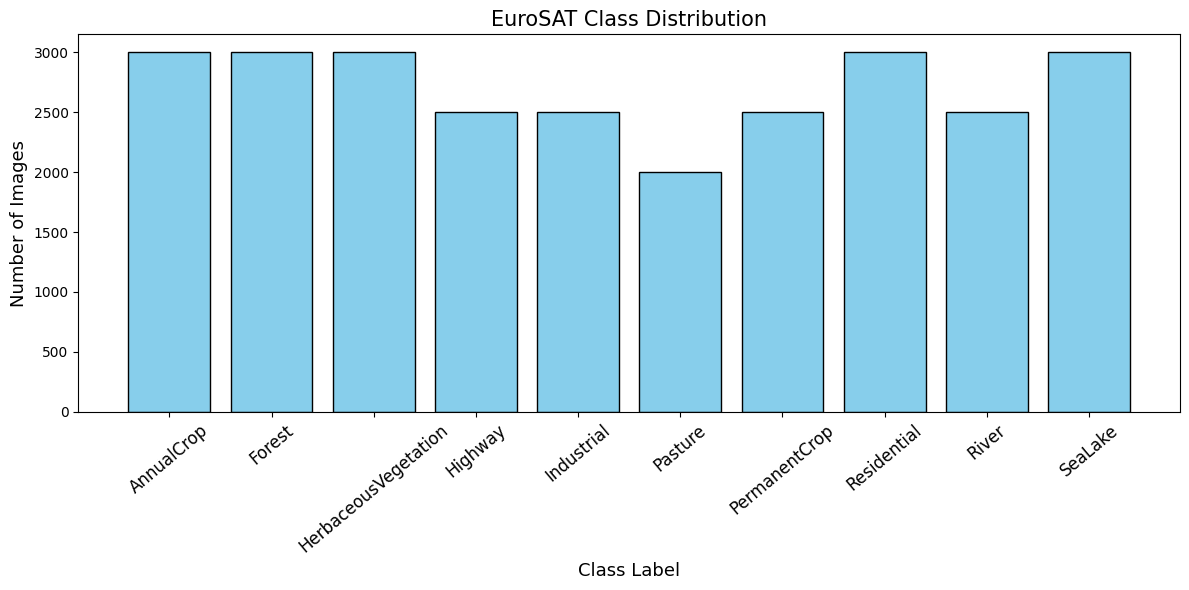

In [5]:
counts = {}

for label in LABELS:
    class_path = os.path.join(DATASET, label)
    counts[label] = len([f for f in os.listdir(class_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])

plt.figure(figsize=(12, 6))
plt.bar(range(len(counts)), list(counts.values()), align='center', color='skyblue', edgecolor='black')
plt.xticks(range(len(counts)), list(counts.keys()), fontsize=12, rotation=40)
plt.xlabel('Class Label', fontsize=13)
plt.ylabel('Number of Images', fontsize=13)
plt.title('EuroSAT Class Distribution', fontsize=15)
plt.tight_layout()
plt.show()

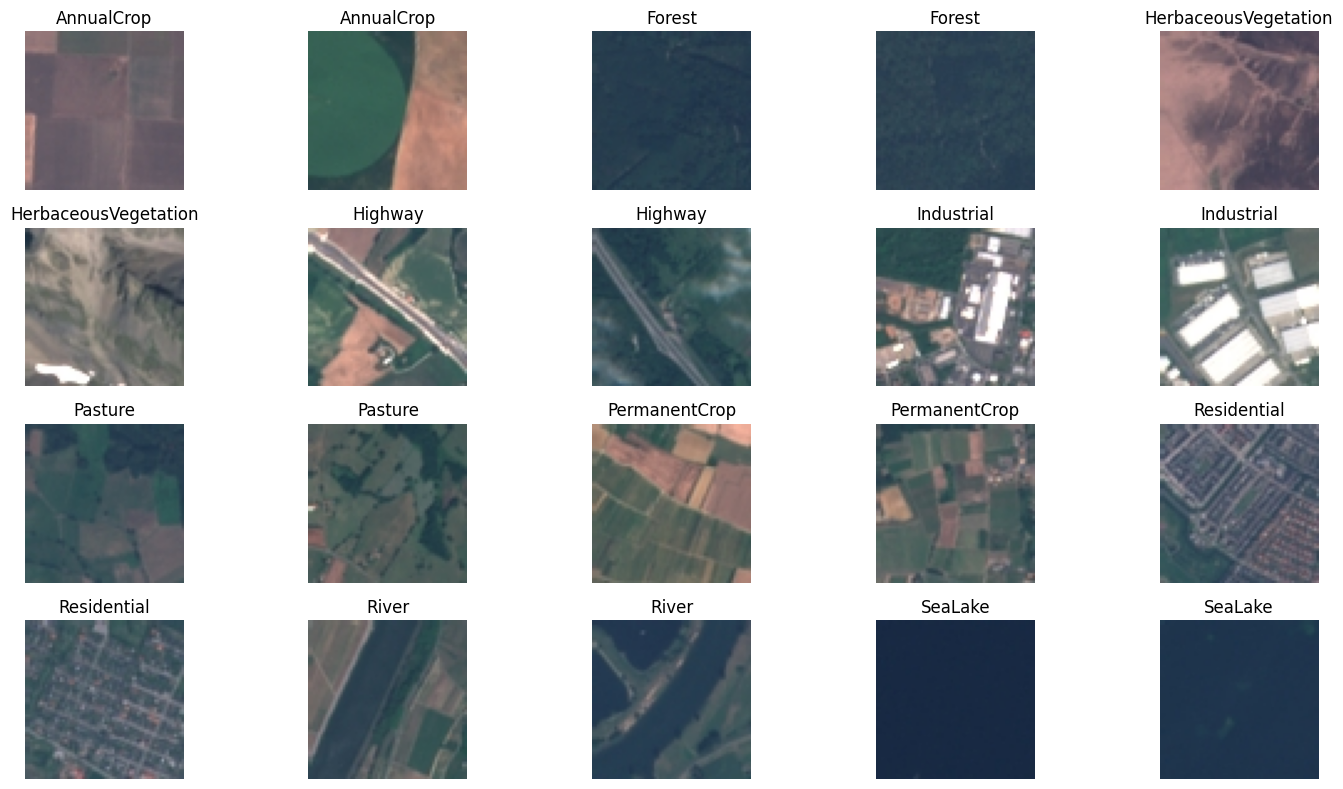

In [6]:
# build img_paths by listing only image files inside class directories
img_paths = []
for l in LABELS:
    class_dir = os.path.join(DATASET, l)
    if not os.path.isdir(class_dir):
        # skip non-directory entries like JSON/CSV files
        continue
    imgs = [f for f in os.listdir(class_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    imgs = sorted(imgs)
    # take up to two example images per class
    for fname in imgs[:2]:
        img_paths.append(os.path.join(class_dir, fname))

def plot_sat_imgs(paths):
    n = min(20, len(paths))
    plt.figure(figsize=(15, 8))
    for i in range(n):
        plt.subplot(4, 5, i+1, xticks=[], yticks=[])
        try:
            img = Image.open(paths[i])
            plt.imshow(np.asarray(img))
            plt.title(os.path.basename(os.path.dirname(paths[i])))
        except Exception:
            plt.text(0.5, 0.5, "Unable to load", ha='center')
        plt.axis('off')
    plt.tight_layout()

plot_sat_imgs(img_paths)

In [7]:

heights, widths = [], []

for label in LABELS:
    class_dir = os.path.join(DATASET, label)
    # skip anything that is not a directory (e.g., json/csv files)
    if not os.path.isdir(class_dir):
        continue

    imgs = [f for f in os.listdir(class_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    for fname in imgs[:100]:  # sample first 100 per class
        try:
            img = Image.open(os.path.join(class_dir, fname))
            w, h = img.size
            widths.append(w)
            heights.append(h)
        except Exception:
            # skip files that can't be opened as images
            continue

if widths and heights:
    print(f"Average width: {np.mean(widths):.2f}, height: {np.mean(heights):.2f}")
else:
    print("No images found to compute sizes.")


Average width: 64.00, height: 64.00


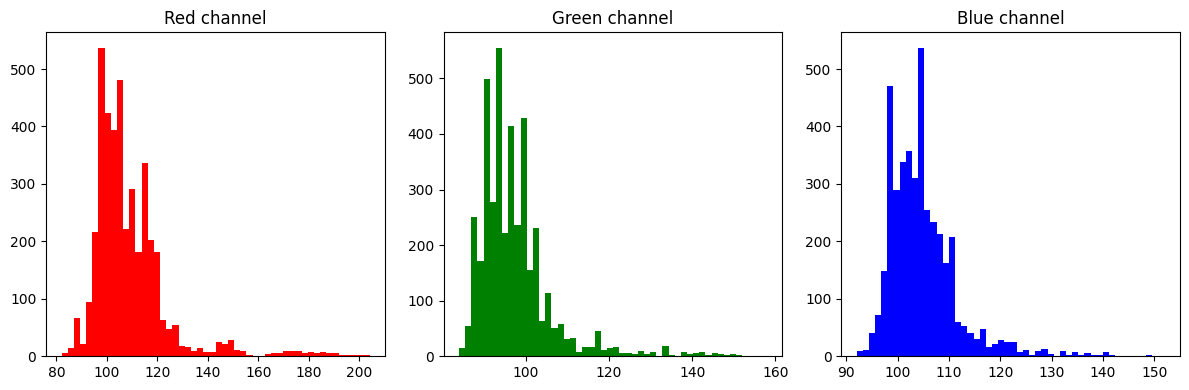

In [8]:
import matplotlib.pyplot as plt

img = np.array(Image.open(os.path.join(DATASET, LABELS[0], os.listdir(os.path.join(DATASET, LABELS[0]))[0])))

plt.figure(figsize=(12,4))
for i, color in enumerate(['Red','Green','Blue']):
    plt.subplot(1,3,i+1)
    plt.hist(img[:,:,i].ravel(), bins=50, color=color.lower())
    plt.title(f'{color} channel')
plt.tight_layout()


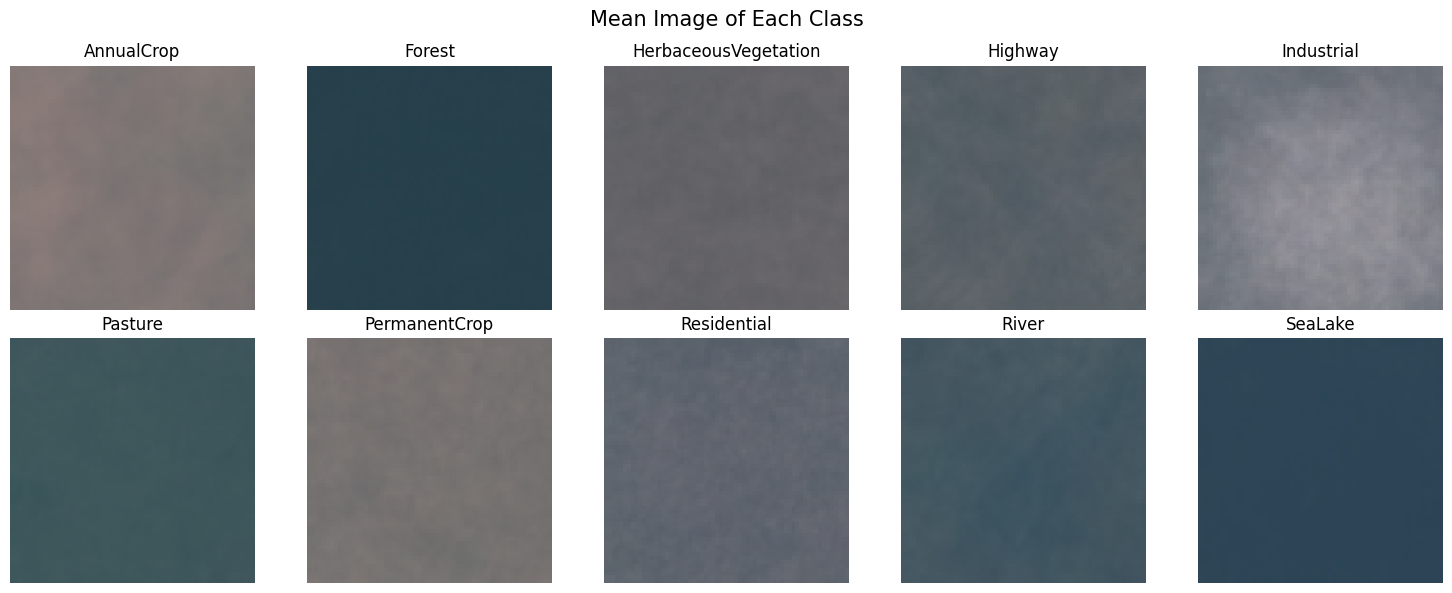

In [9]:
fig, axes = plt.subplots(2,5, figsize=(15,6))
axes = axes.flatten()

# plot up to 10 class mean images, skipping non-directory entries (e.g., json/csv files)
j = 0
for label in LABELS:
    if j >= len(axes):
        break

    class_dir = os.path.join(DATASET, label)
    if not os.path.isdir(class_dir):
        # skip files like label_map.json, train.csv, etc.
        continue

    # collect image files (safely) and load a sample
    img_files = [f for f in sorted(os.listdir(class_dir)) if f.lower().endswith(('.jpg', '.jpeg', '.png'))][:100]
    imgs = []
    for fname in img_files:
        try:
            imgs.append(np.array(Image.open(os.path.join(class_dir, fname))))
        except Exception:
            # skip unreadable images
            continue

    if not imgs:
        continue

    mean_img = np.mean(imgs, axis=0).astype(np.uint8)
    axes[j].imshow(mean_img)
    axes[j].set_title(label)
    axes[j].axis('off')
    j += 1

plt.suptitle('Mean Image of Each Class', fontsize=15)
plt.tight_layout()


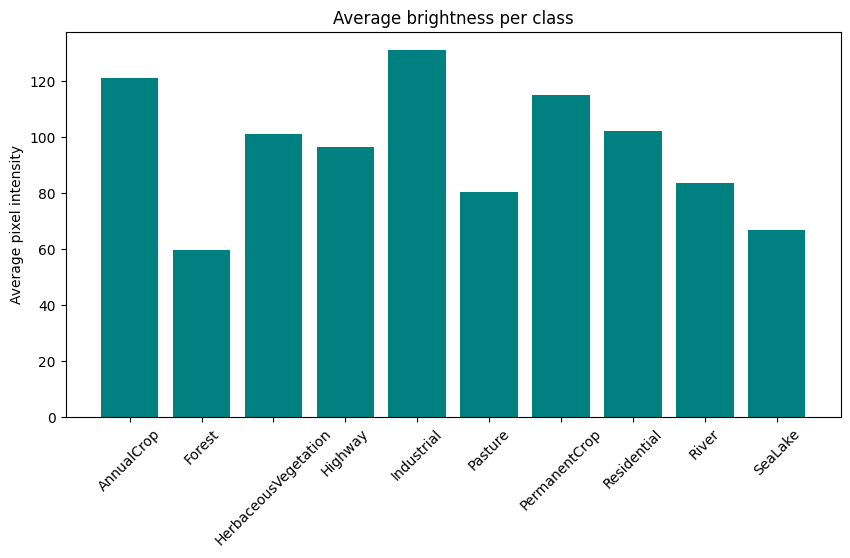

In [10]:
means = {}
for label in LABELS:
    class_dir = os.path.join(DATASET, label)
    if not os.path.isdir(class_dir):
        continue  # skip non-directory entries
    imgs = [np.array(Image.open(os.path.join(class_dir, f))).mean() for f in os.listdir(class_dir)[:100]]
    means[label] = np.mean(imgs)

plt.figure(figsize=(10,5))
plt.bar(means.keys(), means.values(), color='teal')
plt.xticks(rotation=45)
plt.ylabel("Average pixel intensity")
plt.title("Average brightness per class")
plt.show()


# Preprocessing

In [48]:

IMG_SIZE = (64, 64)

X = []
y = []

for label in os.listdir(DATASET):
    class_dir = os.path.join(DATASET, label)
    if os.path.isdir(class_dir):
        for img_name in os.listdir(class_dir): 
            img_path = os.path.join(class_dir, img_name)
            img = cv2.imread(img_path)
            if img is not None:
                img = cv2.resize(img, IMG_SIZE)
                X.append(img)
                y.append(label)

X = np.array(X)
y = np.array(y)
print(" Loaded ALL images:", X.shape)
print(" Total labels:", len(y))



 Loaded ALL images: (27000, 64, 64, 3)
 Total labels: 27000


# Feature Extraction Methods

## HOG Method

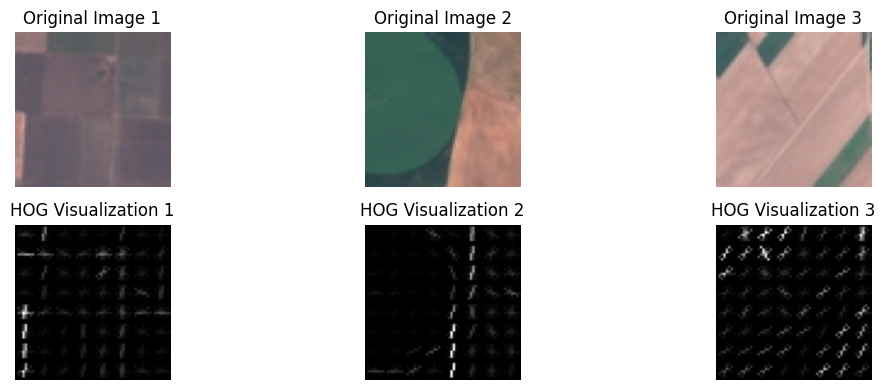

In [16]:

sample_indices = [0, 1, 2] 
plt.figure(figsize=(12, 4))

for i, idx in enumerate(sample_indices):
    img = X[idx]
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    
    # Compute HOG and get visualization image
    fd, hog_image = hog(
        gray,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        visualize=True,
        feature_vector=True
    )
    
    plt.subplot(2, 3, i+1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(f"Original Image {i+1}")
    plt.axis("off")
    
    plt.subplot(2, 3, i+4)
    plt.imshow(hog_image, cmap='gray')
    plt.title(f"HOG Visualization {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()


## Gabor Filter

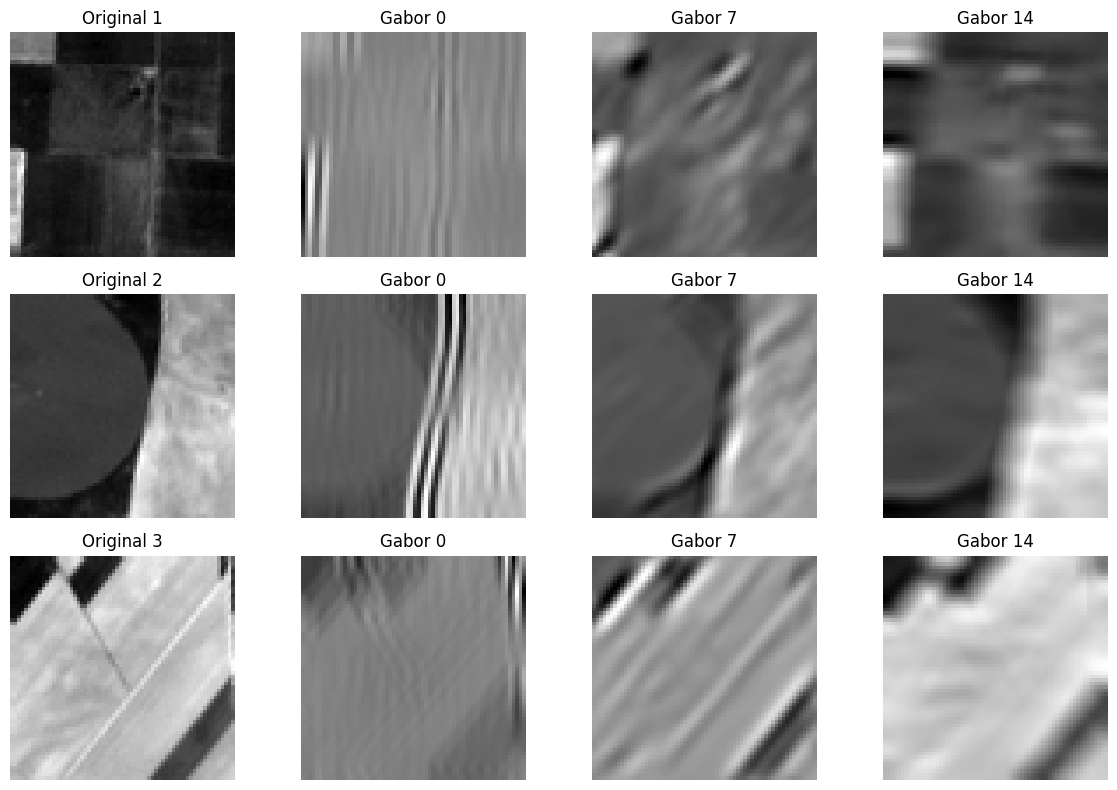

In [ ]:


def build_gabor_kernels(ksize=11, sigma=4.0, gam=0.5, phases=(0,)):
    thetas = np.linspace(0, np.pi, 8, endpoint=False)           
    lambdas = [4, 8, 12]                                        
    kernels = []
    for th in thetas:
        for lam in lambdas:
            for psi in phases:
                k = cv2.getGaborKernel((ksize, ksize), sigma, th, lam, gam, psi, ktype=cv2.CV_32F)
                kernels.append(k)
    return kernels

gabor_kernels = build_gabor_kernels()

# Visualize responses for first 3 images
def show_gabor_examples(X, kernels=gabor_kernels, k_indices=(0, 7, 14)):
    plt.figure(figsize=(12,8))
    for i in range(3):
        img = cv2.cvtColor(X[i], cv2.COLOR_BGR2GRAY)
        plt.subplot(3,4,4*i+1); plt.imshow(img, cmap='gray'); plt.title(f'Original {i+1}'); plt.axis('off')
        for j, ki in enumerate(k_indices):
            resp = cv2.filter2D(img, cv2.CV_32F, kernels[ki])
            resp = (resp - resp.min())/(resp.max()-resp.min()+1e-8)  # normalize for display
            plt.subplot(3,4,4*i+2+j); plt.imshow(resp, cmap='gray'); plt.title(f'Gabor {ki}'); plt.axis('off')
    plt.tight_layout(); plt.show()

show_gabor_examples(X)


##  Color Moments Method

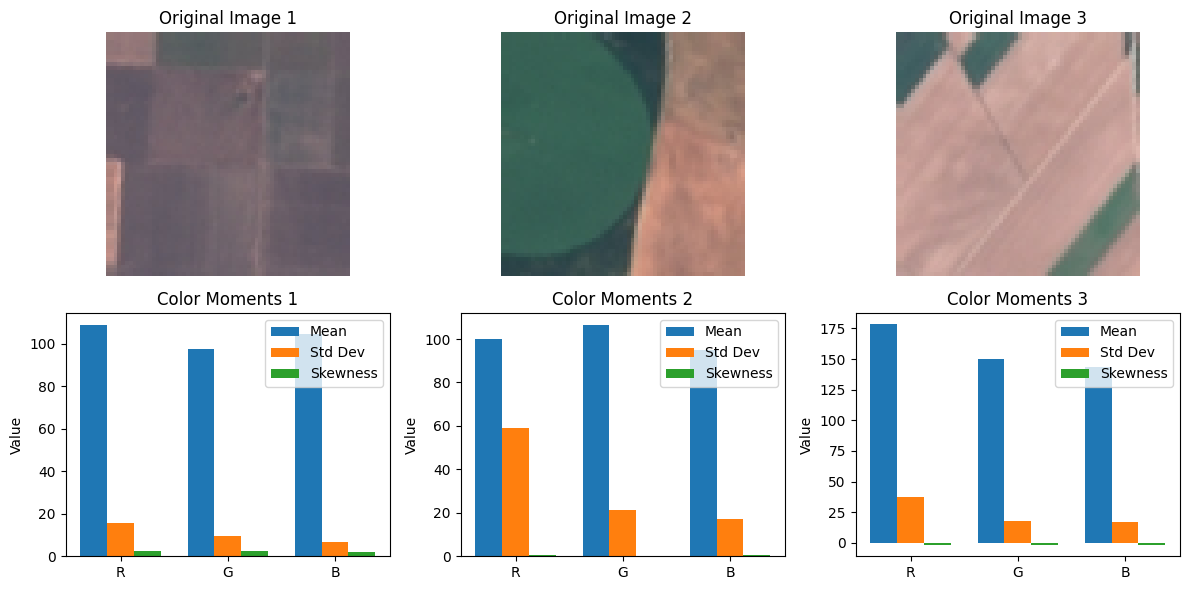

In [50]:
import matplotlib.pyplot as plt
import cv2
import numpy as np
from scipy.stats import skew

sample_indices = [0, 1, 2]  
plt.figure(figsize=(12, 6))

for i, idx in enumerate(sample_indices):
    img = X[idx]
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    # --- Compute Color Moments ---
    means, stds, skews = [], [], []
    for c in range(3):  # R, G, B channels
        channel = img_rgb[:, :, c].ravel()
        means.append(np.mean(channel))
        stds.append(np.std(channel))
        skews.append(skew(channel))
    
    # --- Plot Original Image ---
    plt.subplot(2, 3, i + 1)
    plt.imshow(img_rgb)
    plt.title(f"Original Image {i+1}")
    plt.axis("off")
    
    # --- Plot Color Moments Bar Chart ---
    plt.subplot(2, 3, i + 4)
    x = np.arange(3)
    width = 0.25
    plt.bar(x - width, means, width, label="Mean")
    plt.bar(x, stds, width, label="Std Dev")
    plt.bar(x + width, skews, width, label="Skewness")
    plt.xticks(x, ['R', 'G', 'B'])
    plt.ylabel('Value')
    plt.title(f"Color Moments {i+1}")
    plt.legend()

plt.tight_layout()
plt.show()

## Convert Images to Feature Vectors

In [70]:
def extract_hog_features(images):
    hog_features = []
    for img in images:
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        feature = hog(
            gray,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            visualize=False,
            feature_vector=True
        )
        hog_features.append(feature)
    return np.array(hog_features)

X_hog = extract_hog_features(X)
print(" HOG features shape:", X_hog.shape)

 HOG features shape: (27000, 1764)


In [19]:
def extract_gabor_features(images, kernels):
    features = []
    for img in images:
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        vec = []
        for k in kernels:
            fimg = cv2.filter2D(gray, cv2.CV_32F, k)
            vec.append(fimg.mean())
            vec.append(fimg.std())
        features.append(vec)
    return np.array(features, dtype=np.float32)

X_gabor = extract_gabor_features(X, gabor_kernels)
print(" Gabor features shape:", X_gabor.shape)

 Gabor features shape: (27000, 48)


In [71]:
from scipy.stats import skew

def extract_color_moments(images):
    features = []
    for img in images:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        vec = []
        for i in range(3):  # For each channel: R, G, B
            channel = img[:, :, i].ravel()
            vec.append(np.mean(channel))
            vec.append(np.std(channel))
            vec.append(skew(channel))
        features.append(vec)
    return np.array(features, dtype=np.float32)

# Apply to dataset
X_color = extract_color_moments(X)
print("Color Moments shape:", X_color.shape)


Color Moments shape: (27000, 9)


# ML

In [21]:

from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np


# SVM with Color Method

In [ ]:
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score, f1_score, recall_score, precision_score
import matplotlib.pyplot as plt
import numpy as np


y = np.array(y).ravel()
le = LabelEncoder()
y_encoded = le.fit_transform(y)


scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_color)


svm_model = SVC(kernel='rbf', C=10, gamma='scale', probability=True, random_state=42)


skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
fold_metrics = []
y_preds, y_trues = [], []

for fold, (train_idx, val_idx) in enumerate(skf.split(X_scaled, y_encoded), 1):
    print(f"\n Fold {fold} ------------------------------")
    X_train, X_val = X_scaled[train_idx], X_scaled[val_idx]
    y_train, y_val = y_encoded[train_idx], y_encoded[val_idx]

    svm_model.fit(X_train, y_train)
    y_pred = svm_model.predict(X_val)

    acc = accuracy_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred, average='weighted')
    rec = recall_score(y_val, y_pred, average='weighted')
    pre = precision_score(y_val, y_pred, average='weighted')

   
    print(f"  Accuracy:  {acc:.4f}")
    print(f"  F1-Score:  {f1:.4f}")
    print(f"  Recall:    {rec:.4f}")
    print(f"  Precision: {pre:.4f}")

    fold_metrics.append({'fold': fold, 'accuracy': acc, 'f1': f1, 'recall': rec, 'precision': pre})
    y_preds.append(y_pred)
    y_trues.append(y_val)

best_fold = max(fold_metrics, key=lambda x: x['f1'])
best_idx = best_fold['fold'] - 1
print("\n Best Fold:", best_fold)


 Fold 1 ------------------------------
  Accuracy:  0.8101
  F1-Score:  0.8074
  Recall:    0.8101
  Precision: 0.8064

 Fold 2 ------------------------------
  Accuracy:  0.8030
  F1-Score:  0.7995
  Recall:    0.8030
  Precision: 0.7986

 Fold 3 ------------------------------
  Accuracy:  0.8074
  F1-Score:  0.8046
  Recall:    0.8074
  Precision: 0.8036

 Best Fold: {'fold': 1, 'accuracy': 0.8101111111111111, 'f1': 0.8074293271415495, 'recall': 0.8101111111111111, 'precision': 0.8063693480991692}


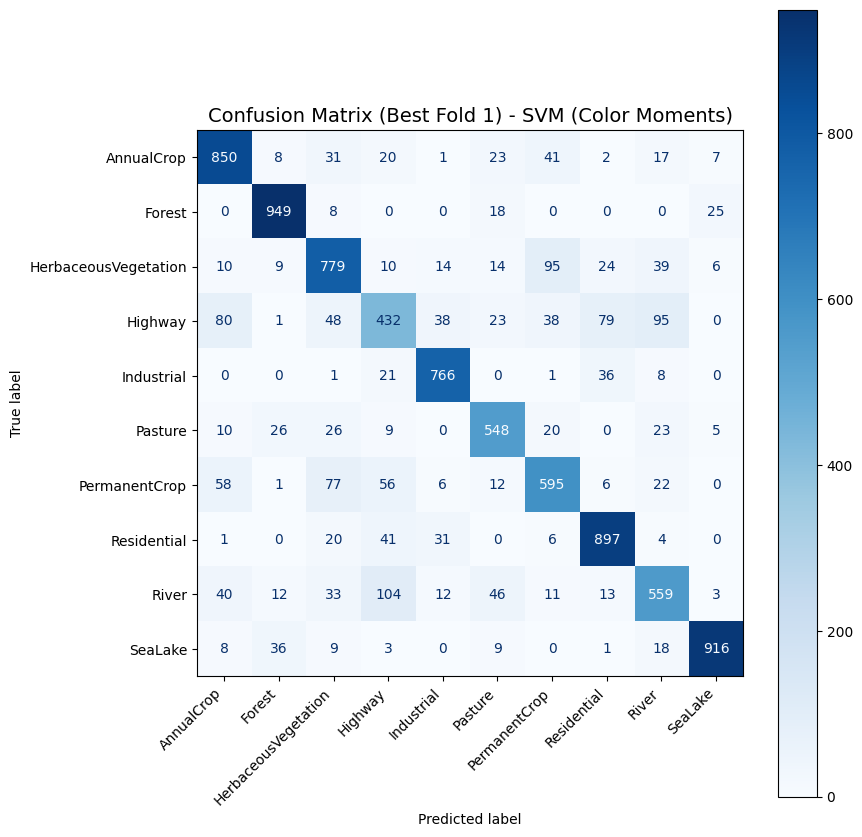

In [24]:
cm = confusion_matrix(y_trues[best_idx], y_preds[best_idx])
fig, ax = plt.subplots(figsize=(9, 9))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(cmap='Blues', values_format='d', ax=ax, colorbar=True)
plt.title(f'Confusion Matrix (Best Fold {best_fold["fold"]}) - SVM (Color Moments)', fontsize=14)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()

In [25]:
print("\nClassification Report (SVM on Color Moments):")
print(classification_report(y_trues[best_idx], y_preds[best_idx], target_names=le.classes_))



Classification Report (SVM on Color Moments):
                      precision    recall  f1-score   support

          AnnualCrop       0.80      0.85      0.83      1000
              Forest       0.91      0.95      0.93      1000
HerbaceousVegetation       0.75      0.78      0.77      1000
             Highway       0.62      0.52      0.56       834
          Industrial       0.88      0.92      0.90       833
             Pasture       0.79      0.82      0.81       667
       PermanentCrop       0.74      0.71      0.73       833
         Residential       0.85      0.90      0.87      1000
               River       0.71      0.67      0.69       833
             SeaLake       0.95      0.92      0.93      1000

            accuracy                           0.81      9000
           macro avg       0.80      0.80      0.80      9000
        weighted avg       0.81      0.81      0.81      9000



# SVM with HOG Method

In [27]:
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score, f1_score, recall_score, precision_score
import matplotlib.pyplot as plt
import numpy as np

# ---------- Encode labels ----------
y = np.array(y).ravel()
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# ---------- Normalize HOG Features ----------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_hog)

# ---------- Initialize SVM ----------
svm_model = SVC(kernel='rbf', C=10, gamma='scale', probability=True, random_state=42)

# ---------- 3-Fold Cross Validation ----------
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
fold_metrics = []
y_preds, y_trues = [], []

for fold, (train_idx, val_idx) in enumerate(skf.split(X_scaled, y_encoded), 1):
    print(f"\n Fold {fold} ------------------------------")
    X_train, X_val = X_scaled[train_idx], X_scaled[val_idx]
    y_train, y_val = y_encoded[train_idx], y_encoded[val_idx]

    svm_model.fit(X_train, y_train)
    y_pred = svm_model.predict(X_val)

    acc = accuracy_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred, average='weighted')
    rec = recall_score(y_val, y_pred, average='weighted')
    pre = precision_score(y_val, y_pred, average='weighted')

    # Print metrics for each fold
    print(f"  Accuracy:  {acc:.4f}")
    print(f"  F1-Score:  {f1:.4f}")
    print(f"  Recall:    {rec:.4f}")
    print(f"  Precision: {pre:.4f}")

    fold_metrics.append({'fold': fold, 'accuracy': acc, 'f1': f1, 'recall': rec, 'precision': pre})
    y_preds.append(y_pred)
    y_trues.append(y_val)

# ---------- Best Fold ----------
best_fold = max(fold_metrics, key=lambda x: x['f1'])
best_idx = best_fold['fold'] - 1
print("\n Best Fold Result:")
print(f"  Fold {best_fold['fold']} → Accuracy: {best_fold['accuracy']:.4f}, "
      f"F1: {best_fold['f1']:.4f}, Recall: {best_fold['recall']:.4f}, Precision: {best_fold['precision']:.4f}")



 Fold 1 ------------------------------
  Accuracy:  0.7437
  F1-Score:  0.7431
  Recall:    0.7437
  Precision: 0.7465

 Fold 2 ------------------------------
  Accuracy:  0.7424
  F1-Score:  0.7411
  Recall:    0.7424
  Precision: 0.7425

 Fold 3 ------------------------------
  Accuracy:  0.7443
  F1-Score:  0.7443
  Recall:    0.7443
  Precision: 0.7475

 Best Fold Result:
  Fold 3 → Accuracy: 0.7443, F1: 0.7443, Recall: 0.7443, Precision: 0.7475


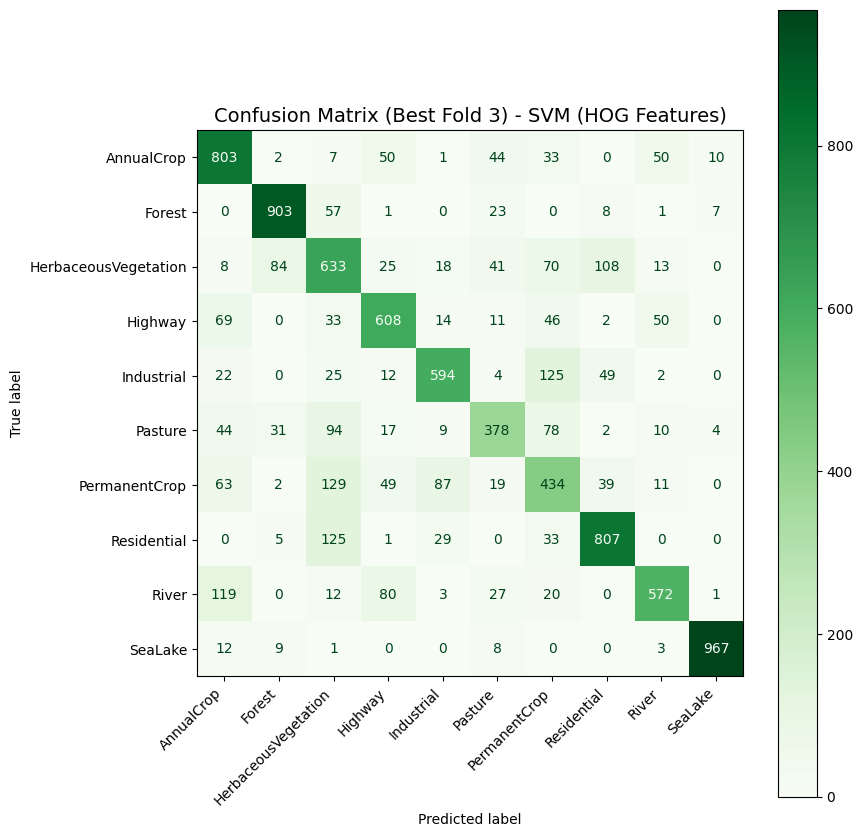

In [28]:
# ---------- Confusion Matrix ----------
cm = confusion_matrix(y_trues[best_idx], y_preds[best_idx])
fig, ax = plt.subplots(figsize=(9, 9))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(cmap='Greens', values_format='d', ax=ax, colorbar=True)
plt.title(f'Confusion Matrix (Best Fold {best_fold["fold"]}) - SVM (HOG Features)', fontsize=14)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()

In [29]:
print("\n Classification Report (SVM on HOG Features):")
print(classification_report(y_trues[best_idx], y_preds[best_idx], target_names=le.classes_))



 Classification Report (SVM on HOG Features):
                      precision    recall  f1-score   support

          AnnualCrop       0.70      0.80      0.75      1000
              Forest       0.87      0.90      0.89      1000
HerbaceousVegetation       0.57      0.63      0.60      1000
             Highway       0.72      0.73      0.73       833
          Industrial       0.79      0.71      0.75       833
             Pasture       0.68      0.57      0.62       667
       PermanentCrop       0.52      0.52      0.52       833
         Residential       0.80      0.81      0.80      1000
               River       0.80      0.69      0.74       834
             SeaLake       0.98      0.97      0.97      1000

            accuracy                           0.74      9000
           macro avg       0.74      0.73      0.74      9000
        weighted avg       0.75      0.74      0.74      9000



# KNN With Color Method

In [30]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score, f1_score, recall_score, precision_score
import matplotlib.pyplot as plt
import numpy as np

# ---------- Encode labels ----------
y = np.array(y).ravel()
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# ---------- Normalize Color Moments ----------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_color)

# ---------- Initialize KNN ----------
# You can tune n_neighbors (default here = 5)
knn_model = KNeighborsClassifier(n_neighbors=5, weights='distance', metric='euclidean')

# ---------- 3-Fold Cross Validation ----------
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
fold_metrics = []
y_preds, y_trues = [], []

for fold, (train_idx, val_idx) in enumerate(skf.split(X_scaled, y_encoded), 1):
    print(f"\n Fold {fold} ------------------------------")
    X_train, X_val = X_scaled[train_idx], X_scaled[val_idx]
    y_train, y_val = y_encoded[train_idx], y_encoded[val_idx]

    knn_model.fit(X_train, y_train)
    y_pred = knn_model.predict(X_val)

    acc = accuracy_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred, average='weighted')
    rec = recall_score(y_val, y_pred, average='weighted')
    pre = precision_score(y_val, y_pred, average='weighted')

    # Print metrics for each fold
    print(f"  Accuracy:  {acc:.4f}")
    print(f"  F1-Score:  {f1:.4f}")
    print(f"  Recall:    {rec:.4f}")
    print(f"  Precision: {pre:.4f}")

    fold_metrics.append({'fold': fold, 'accuracy': acc, 'f1': f1, 'recall': rec, 'precision': pre})
    y_preds.append(y_pred)
    y_trues.append(y_val)

# ---------- Best Fold ----------
best_fold = max(fold_metrics, key=lambda x: x['f1'])
best_idx = best_fold['fold'] - 1
print("\n Best Fold Result:")
print(f"  Fold {best_fold['fold']} → Accuracy: {best_fold['accuracy']:.4f}, "
      f"F1: {best_fold['f1']:.4f}, Recall: {best_fold['recall']:.4f}, Precision: {best_fold['precision']:.4f}")



 Fold 1 ------------------------------
  Accuracy:  0.7510
  F1-Score:  0.7474
  Recall:    0.7510
  Precision: 0.7485

 Fold 2 ------------------------------
  Accuracy:  0.7450
  F1-Score:  0.7403
  Recall:    0.7450
  Precision: 0.7412

 Fold 3 ------------------------------
  Accuracy:  0.7453
  F1-Score:  0.7419
  Recall:    0.7453
  Precision: 0.7437

 Best Fold Result:
  Fold 1 → Accuracy: 0.7510, F1: 0.7474, Recall: 0.7510, Precision: 0.7485


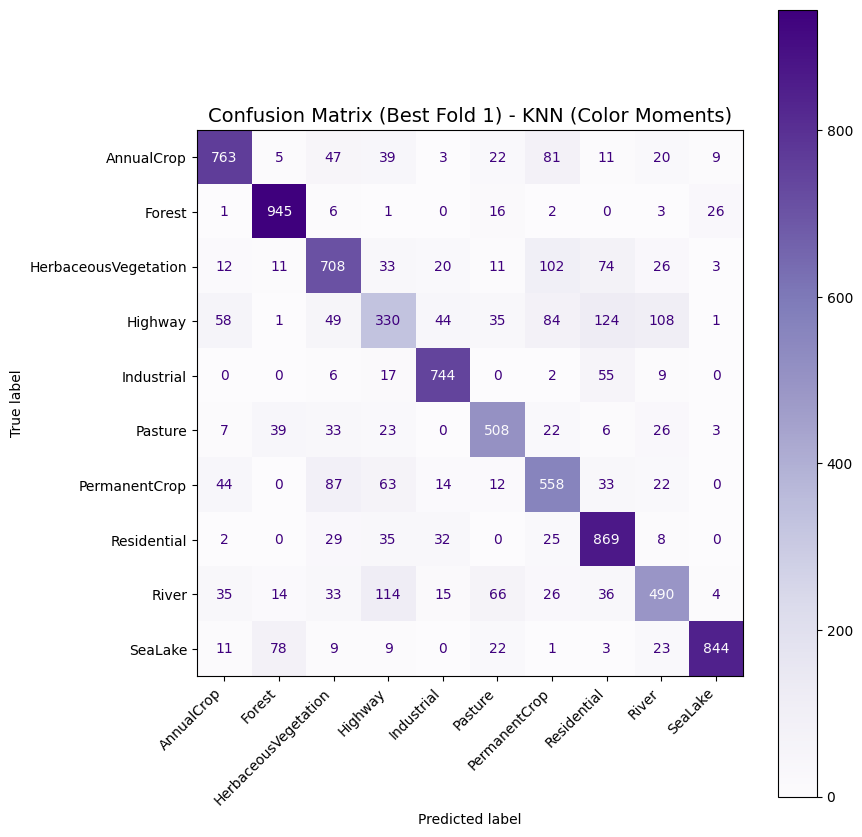

In [31]:
# ---------- Confusion Matrix ----------
cm = confusion_matrix(y_trues[best_idx], y_preds[best_idx])
fig, ax = plt.subplots(figsize=(9, 9))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(cmap='Purples', values_format='d', ax=ax, colorbar=True)
plt.title(f'Confusion Matrix (Best Fold {best_fold["fold"]}) - KNN (Color Moments)', fontsize=14)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()

In [32]:
print("\n Classification Report (KNN on Color Moments):")
print(classification_report(y_trues[best_idx], y_preds[best_idx], target_names=le.classes_))



 Classification Report (KNN on Color Moments):
                      precision    recall  f1-score   support

          AnnualCrop       0.82      0.76      0.79      1000
              Forest       0.86      0.94      0.90      1000
HerbaceousVegetation       0.70      0.71      0.71      1000
             Highway       0.50      0.40      0.44       834
          Industrial       0.85      0.89      0.87       833
             Pasture       0.73      0.76      0.75       667
       PermanentCrop       0.62      0.67      0.64       833
         Residential       0.72      0.87      0.79      1000
               River       0.67      0.59      0.62       833
             SeaLake       0.95      0.84      0.89      1000

            accuracy                           0.75      9000
           macro avg       0.74      0.74      0.74      9000
        weighted avg       0.75      0.75      0.75      9000



# KNN With Hog

In [33]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score, f1_score, recall_score, precision_score
import matplotlib.pyplot as plt
import numpy as np

# ---------- Encode labels ----------
y = np.array(y).ravel()
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# ---------- Normalize HOG Features ----------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_hog)

# ---------- Initialize KNN ----------
# You can tune n_neighbors later (default 5)
knn_model = KNeighborsClassifier(n_neighbors=5, weights='distance', metric='euclidean')

# ---------- 3-Fold Cross Validation ----------
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
fold_metrics = []
y_preds, y_trues = [], []

for fold, (train_idx, val_idx) in enumerate(skf.split(X_scaled, y_encoded), 1):
    print(f"\n Fold {fold} ------------------------------")
    X_train, X_val = X_scaled[train_idx], X_scaled[val_idx]
    y_train, y_val = y_encoded[train_idx], y_encoded[val_idx]

    knn_model.fit(X_train, y_train)
    y_pred = knn_model.predict(X_val)

    acc = accuracy_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred, average='weighted')
    rec = recall_score(y_val, y_pred, average='weighted')
    pre = precision_score(y_val, y_pred, average='weighted')

    # Print metrics per fold
    print(f"  Accuracy:  {acc:.4f}")
    print(f"  F1-Score:  {f1:.4f}")
    print(f"  Recall:    {rec:.4f}")
    print(f"  Precision: {pre:.4f}")

    fold_metrics.append({'fold': fold, 'accuracy': acc, 'f1': f1, 'recall': rec, 'precision': pre})
    y_preds.append(y_pred)
    y_trues.append(y_val)

# ---------- Best Fold ----------
best_fold = max(fold_metrics, key=lambda x: x['f1'])
best_idx = best_fold['fold'] - 1
print("\n Best Fold Result:")
print(f"  Fold {best_fold['fold']} → Accuracy: {best_fold['accuracy']:.4f}, "
      f"F1: {best_fold['f1']:.4f}, Recall: {best_fold['recall']:.4f}, Precision: {best_fold['precision']:.4f}")



 Fold 1 ------------------------------
  Accuracy:  0.4184
  F1-Score:  0.3669
  Recall:    0.4184
  Precision: 0.4701

 Fold 2 ------------------------------
  Accuracy:  0.4202
  F1-Score:  0.3673
  Recall:    0.4202
  Precision: 0.4684

 Fold 3 ------------------------------
  Accuracy:  0.4177
  F1-Score:  0.3631
  Recall:    0.4177
  Precision: 0.4718

 Best Fold Result:
  Fold 2 → Accuracy: 0.4202, F1: 0.3673, Recall: 0.4202, Precision: 0.4684


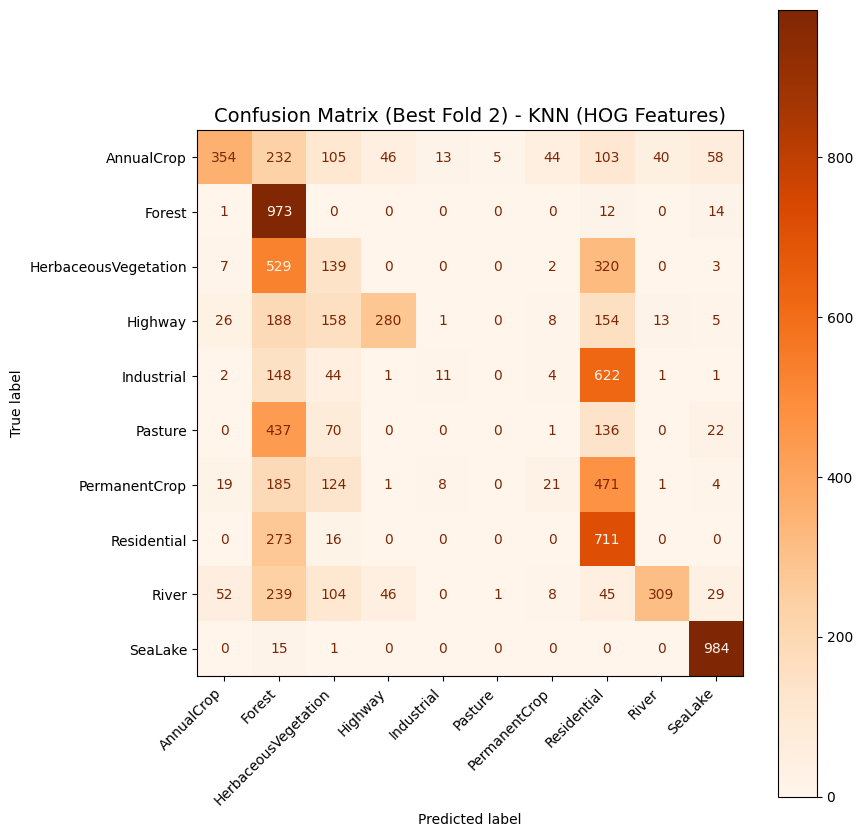

In [ ]:
cm = confusion_matrix(y_trues[best_idx], y_preds[best_idx])
fig, ax = plt.subplots(figsize=(9, 9))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(cmap='Oranges', values_format='d', ax=ax, colorbar=True)
plt.title(f'Confusion Matrix (Best Fold {best_fold["fold"]}) - KNN (HOG Features)', fontsize=14)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()
plt.show() 


In [35]:
print("\n Classification Report (KNN on HOG Features):")
print(classification_report(y_trues[best_idx], y_preds[best_idx], target_names=le.classes_))



 Classification Report (KNN on HOG Features):
                      precision    recall  f1-score   support

          AnnualCrop       0.77      0.35      0.48      1000
              Forest       0.30      0.97      0.46      1000
HerbaceousVegetation       0.18      0.14      0.16      1000
             Highway       0.75      0.34      0.46       833
          Industrial       0.33      0.01      0.03       834
             Pasture       0.00      0.00      0.00       666
       PermanentCrop       0.24      0.03      0.05       834
         Residential       0.28      0.71      0.40      1000
               River       0.85      0.37      0.52       833
             SeaLake       0.88      0.98      0.93      1000

            accuracy                           0.42      9000
           macro avg       0.46      0.39      0.35      9000
        weighted avg       0.47      0.42      0.37      9000



# DL

# ANN with Color Method

In [ ]:
# ---------- Encode labels ----------
y = np.array(y).ravel()
le = LabelEncoder()
y_encoded = le.fit_transform(y)
num_classes = len(np.unique(y_encoded))
y_categorical = to_categorical(y_encoded, num_classes)

# ---------- Normalize Color Moments ----------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_color)

# ---------- Define ANN model ----------
def build_ann(input_dim, output_dim, lr=1e-3):
    model = Sequential([
        Dense(256, activation='relu', input_dim=input_dim),
        BatchNormalization(),
        Dropout(0.3),

        Dense(128, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),

        Dense(output_dim, activation='softmax')
    ])
    model.compile(optimizer=Adam(learning_rate=lr),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

# ---------- 3-Fold Cross Validation ----------
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
histories, fold_metrics = [], []
y_preds, y_trues = [], []

# NEW: track best model across folds
best_model = None
best_f1 = -1.0   # something very small
best_fold_info = None

for fold, (train_idx, val_idx) in enumerate(skf.split(X_scaled, y_encoded), 1):
    print(f"\n Fold {fold} ------------------------------")
    X_train, X_val = X_scaled[train_idx], X_scaled[val_idx]
    y_train, y_val = y_categorical[train_idx], y_categorical[val_idx]

    model = build_ann(X_scaled.shape[1], num_classes)

    early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=80,
        batch_size=64,
        callbacks=[early_stop],
        verbose=1
    )

    y_pred = np.argmax(model.predict(X_val), axis=1)
    y_true = y_encoded[val_idx]

    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average='weighted')
    rec = recall_score(y_true, y_pred, average='weighted')
    pre = precision_score(y_true, y_pred, average='weighted')

    fold_metrics.append({'fold': fold, 'accuracy': acc, 'f1': f1, 'recall': rec, 'precision': pre})
    histories.append(history)
    y_preds.append(y_pred)
    y_trues.append(y_true)

    # --------- UPDATE BEST MODEL HERE ----------
    if f1 > best_f1:
        best_f1 = f1
        best_model = model
        best_fold_info = {'fold': fold, 'accuracy': acc, 'f1': f1, 'recall': rec, 'precision': pre}

# ---------- Find Best Fold ----------
best_fold = max(fold_metrics, key=lambda x: x['f1'])
print("\n Best Fold (from metrics list):", best_fold)
print("\n Best Fold (from tracking):", best_fold_info)

# ---------- Save Best Fold Weights ----------
if best_model is not None:
    # change the name if you want a different one
    best_model.save_weights("ann_color_best_weights.weights.h5")



 Fold 1 ------------------------------
Epoch 1/80


<local-eurosat>\tfenv\lib\site-packages\keras\src\layers\core\dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


282/282 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.4966 - loss: 1.5128 - val_accuracy: 0.5931 - val_loss: 1.2503
Epoch 2/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6806 - loss: 0.9061 - val_accuracy: 0.7438 - val_loss: 0.7412
Epoch 3/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7102 - loss: 0.8184 - val_accuracy: 0.7721 - val_loss: 0.6468
Epoch 4/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7320 - loss: 0.7624 - val_accuracy: 0.7841 - val_loss: 0.6071
Epoch 5/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7359 - loss: 0.7275 - val_accuracy: 0.7844 - val_loss: 0.6086
Epoch 6/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7476 - loss: 0.7105 - val_accuracy: 0.7928 - val_loss: 0.5787
Epoch 7/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7564 - loss: 0.6925 - val_accuracy: 0.7957 - val_loss: 0.5821
Epoch 8/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7568 - loss: 0.6803 - val_accuracy: 0.7927 - val

<local-eurosat>\tfenv\lib\site-packages\keras\src\layers\core\dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


282/282 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.5083 - loss: 1.4701 - val_accuracy: 0.6351 - val_loss: 1.2221
Epoch 2/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6772 - loss: 0.9131 - val_accuracy: 0.7540 - val_loss: 0.7386
Epoch 3/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7150 - loss: 0.8134 - val_accuracy: 0.7694 - val_loss: 0.6498
Epoch 4/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7287 - loss: 0.7599 - val_accuracy: 0.7790 - val_loss: 0.6168
Epoch 5/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7438 - loss: 0.7311 - val_accuracy: 0.7910 - val_loss: 0.5908
Epoch 6/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7472 - loss: 0.7073 - val_accuracy: 0.7884 - val_loss: 0.5794
Epoch 7/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7616 - loss: 0.6837 - val_accuracy: 0.7940 - val_loss: 0.5739
Epoch 8/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7596 - loss: 0.6779 - val_accuracy: 0.7979 - val_

<local-eurosat>\tfenv\lib\site-packages\keras\src\layers\core\dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


282/282 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.5049 - loss: 1.4822 - val_accuracy: 0.6673 - val_loss: 1.1902
Epoch 2/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6793 - loss: 0.9186 - val_accuracy: 0.7502 - val_loss: 0.7279
Epoch 3/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7088 - loss: 0.8194 - val_accuracy: 0.7812 - val_loss: 0.6278
Epoch 4/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7299 - loss: 0.7614 - val_accuracy: 0.7819 - val_loss: 0.6173
Epoch 5/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7388 - loss: 0.7238 - val_accuracy: 0.7891 - val_loss: 0.5907
Epoch 6/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7614 - loss: 0.6825 - val_accuracy: 0.7883 - val_loss: 0.5863
Epoch 7/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7573 - loss: 0.6759 - val_accuracy: 0.7974 - val_loss: 0.5637
Epoch 8/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7653 - loss: 0.6636 - val_accuracy: 0.7989 - val_

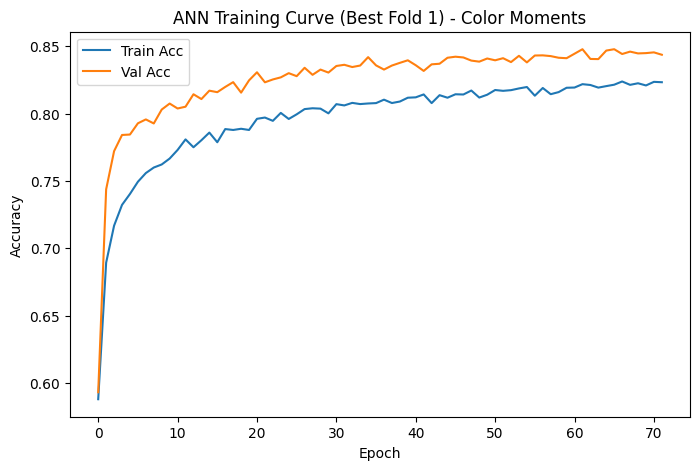

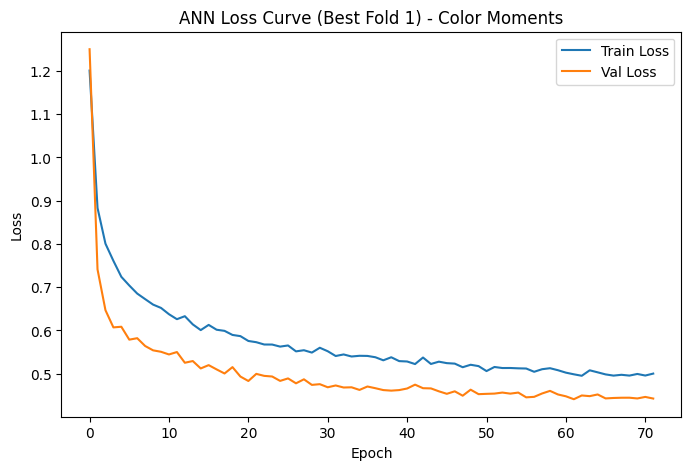

In [77]:
best_history = histories[best_fold['fold'] - 1]
plt.figure(figsize=(8,5))
plt.plot(best_history.history['accuracy'], label='Train Acc')
plt.plot(best_history.history['val_accuracy'], label='Val Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title(f'ANN Training Curve (Best Fold {best_fold["fold"]}) - Color Moments')
plt.legend()
plt.show()

# ---------- Plot Loss Curve ----------
plt.figure(figsize=(8,5))
plt.plot(best_history.history['loss'], label='Train Loss')
plt.plot(best_history.history['val_loss'], label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title(f'ANN Loss Curve (Best Fold {best_fold["fold"]}) - Color Moments')
plt.legend()
plt.show()

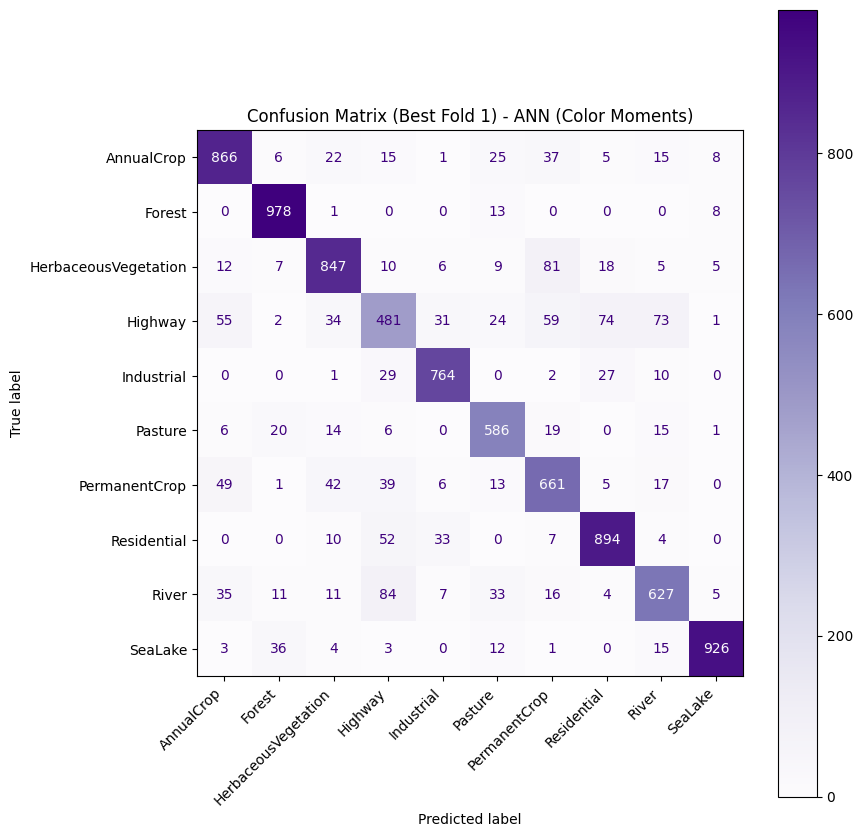

In [78]:
from sklearn.metrics import classification_report

# Select best fold results
best_idx = best_fold['fold'] - 1
y_true_best = y_trues[best_idx]
y_pred_best = y_preds[best_idx]

# Compute confusion matrix
cm = confusion_matrix(y_true_best, y_pred_best, labels=np.arange(num_classes))

# Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(9,9))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(cmap='Purples', values_format='d', ax=ax, colorbar=True)
plt.title(f'Confusion Matrix (Best Fold {best_fold["fold"]}) - ANN (Color Moments)')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [80]:
print(f"\nClassification Report (Best Fold {best_fold['fold']}) - ANN (Color Moments):")
print(classification_report(y_true_best, y_pred_best, target_names=le.classes_))



Classification Report (Best Fold 1) - ANN (Color Moments):
                      precision    recall  f1-score   support

          AnnualCrop       0.84      0.87      0.85      1000
              Forest       0.92      0.98      0.95      1000
HerbaceousVegetation       0.86      0.85      0.85      1000
             Highway       0.67      0.58      0.62       834
          Industrial       0.90      0.92      0.91       833
             Pasture       0.82      0.88      0.85       667
       PermanentCrop       0.75      0.79      0.77       833
         Residential       0.87      0.89      0.88      1000
               River       0.80      0.75      0.78       833
             SeaLake       0.97      0.93      0.95      1000

            accuracy                           0.85      9000
           macro avg       0.84      0.84      0.84      9000
        weighted avg       0.85      0.85      0.85      9000



# ANN with Hog

In [72]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# ---------- Encode labels ----------
y = np.array(y).ravel()
le = LabelEncoder()
y_encoded = le.fit_transform(y)
num_classes = len(np.unique(y_encoded))
y_categorical = to_categorical(y_encoded, num_classes)

# ---------- Normalize HOG features ----------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_hog)

# ---------- Define ANN model ----------
def build_ann(input_dim, output_dim, lr=1e-3):
    model = Sequential([
        Dense(512, activation='relu', input_dim=input_dim),
        BatchNormalization(),
        Dropout(0.3),

        Dense(256, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),

        Dense(output_dim, activation='softmax')
    ])
    model.compile(optimizer=Adam(learning_rate=lr),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

# ---------- 3-Fold Cross Validation ----------
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
histories, fold_metrics = [], []
y_preds, y_trues = [], []

for fold, (train_idx, val_idx) in enumerate(skf.split(X_scaled, y_encoded), 1):
    print(f"\n Fold {fold} ------------------------------")
    X_train, X_val = X_scaled[train_idx], X_scaled[val_idx]
    y_train, y_val = y_categorical[train_idx], y_categorical[val_idx]

    model = build_ann(X_scaled.shape[1], num_classes)

    early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=80,
        batch_size=64,
        callbacks=[early_stop],
        verbose=1
    )

    y_pred = np.argmax(model.predict(X_val), axis=1)
    y_true = y_encoded[val_idx]

    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average='weighted')
    rec = recall_score(y_true, y_pred, average='weighted')
    pre = precision_score(y_true, y_pred, average='weighted')

    fold_metrics.append({'fold': fold, 'accuracy': acc, 'f1': f1, 'recall': rec, 'precision': pre})
    histories.append(history)
    y_preds.append(y_pred)
    y_trues.append(y_true)

# ---------- Find Best Fold ----------
best_fold = max(fold_metrics, key=lambda x: x['f1'])
print("\n Best Fold:", best_fold)


 Fold 1 ------------------------------


<local-eurosat>\tfenv\lib\site-packages\keras\src\layers\core\dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - accuracy: 0.5346 - loss: 1.4057 - val_accuracy: 0.7041 - val_loss: 0.8341
Epoch 2/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.7251 - loss: 0.7634 - val_accuracy: 0.7333 - val_loss: 0.7371
Epoch 3/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.7757 - loss: 0.6218 - val_accuracy: 0.7316 - val_loss: 0.7501
Epoch 4/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.8093 - loss: 0.5230 - val_accuracy: 0.7268 - val_loss: 0.7660
Epoch 5/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.8330 - loss: 0.4582 - val_accuracy: 0.7294 - val_loss: 0.7832
Epoch 6/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.8510 - loss: 0.4123 - val_accuracy: 0.7302 - val_loss: 0.8152
Epoch 7/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.8704 - loss: 0.3532 - val_accuracy: 0.7233 - val_loss: 0.8382
Epoch 8/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.8871 - loss: 0.3136 - val_accu

<local-eurosat>\tfenv\lib\site-packages\keras\src\layers\core\dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


282/282 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.5267 - loss: 1.4724 - val_accuracy: 0.7036 - val_loss: 0.8321
Epoch 2/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.7250 - loss: 0.7564 - val_accuracy: 0.7291 - val_loss: 0.7531
Epoch 3/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.7765 - loss: 0.6160 - val_accuracy: 0.7332 - val_loss: 0.7456
Epoch 4/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.8027 - loss: 0.5490 - val_accuracy: 0.7308 - val_loss: 0.7489
Epoch 5/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.8434 - loss: 0.4532 - val_accuracy: 0.7347 - val_loss: 0.7568
Epoch 6/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.8591 - loss: 0.3975 - val_accuracy: 0.7337 - val_loss: 0.7914
Epoch 7/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.8756 - loss: 0.3436 - val_accuracy: 0.7293 - val_loss: 0.8226
Epoch 8/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.8889 - loss: 0.3068 - val_accuracy: 0.726

<local-eurosat>\tfenv\lib\site-packages\keras\src\layers\core\dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - accuracy: 0.5229 - loss: 1.4495 - val_accuracy: 0.7068 - val_loss: 0.8142
Epoch 2/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.7306 - loss: 0.7528 - val_accuracy: 0.7262 - val_loss: 0.7502
Epoch 3/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.7710 - loss: 0.6302 - val_accuracy: 0.7332 - val_loss: 0.7431
Epoch 4/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.8074 - loss: 0.5433 - val_accuracy: 0.7300 - val_loss: 0.7497
Epoch 5/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.8263 - loss: 0.4768 - val_accuracy: 0.7322 - val_loss: 0.7668
Epoch 6/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.8556 - loss: 0.4049 - val_accuracy: 0.7340 - val_loss: 0.7870
Epoch 7/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.8726 - loss: 0.3579 - val_accuracy: 0.7208 - val_loss: 0.8536
Epoch 8/80
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.8842 - loss: 0.3202 - val_accu

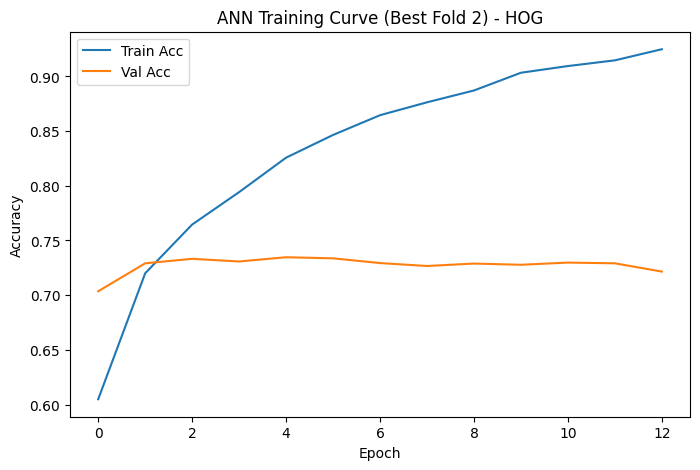

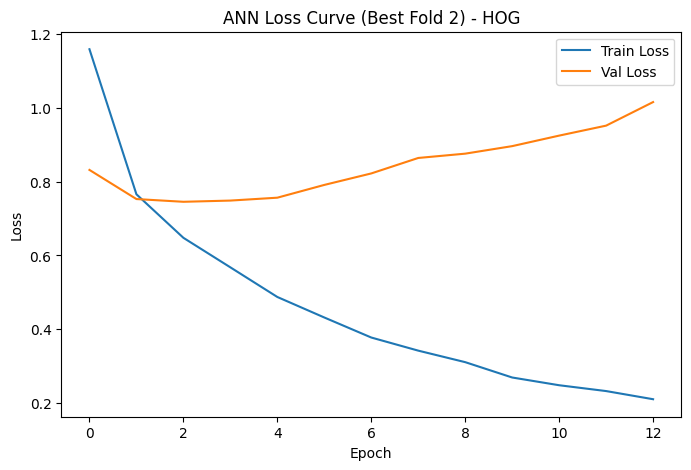

In [73]:
best_history = histories[best_fold['fold'] - 1]
plt.figure(figsize=(8,5))
plt.plot(best_history.history['accuracy'], label='Train Acc')
plt.plot(best_history.history['val_accuracy'], label='Val Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title(f'ANN Training Curve (Best Fold {best_fold["fold"]}) - HOG')
plt.legend()
plt.show()

# ---------- Plot Loss Curve ----------
plt.figure(figsize=(8,5))
plt.plot(best_history.history['loss'], label='Train Loss')
plt.plot(best_history.history['val_loss'], label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title(f'ANN Loss Curve (Best Fold {best_fold["fold"]}) - HOG')
plt.legend()
plt.show()

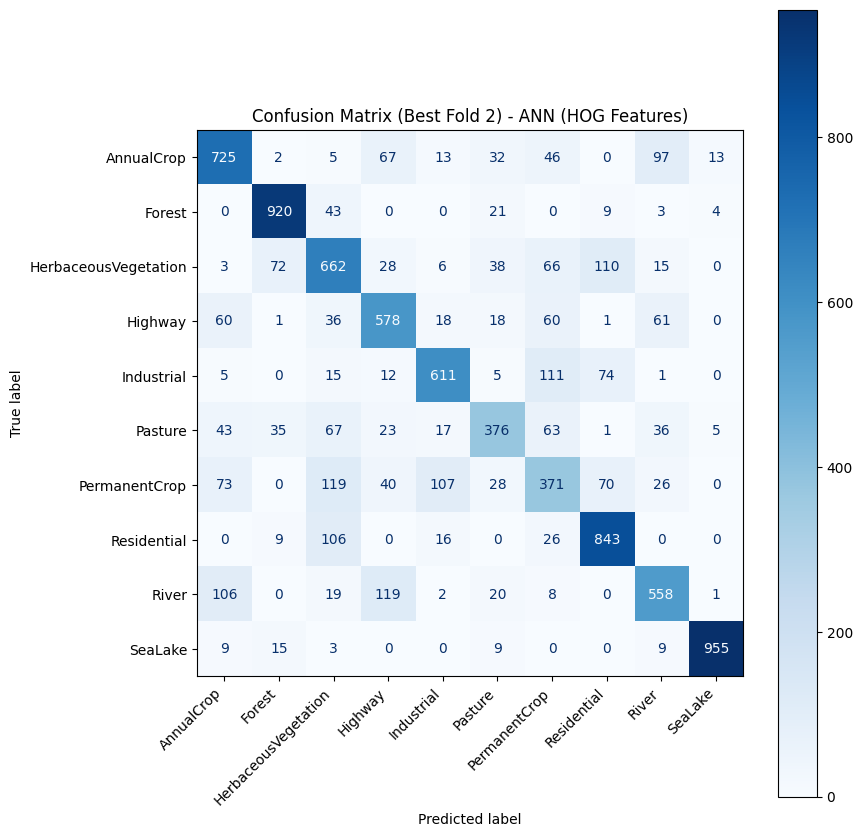

In [74]:
best_idx = best_fold['fold'] - 1
y_true_best = y_trues[best_idx]
y_pred_best = y_preds[best_idx]

# Compute confusion matrix
cm = confusion_matrix(y_true_best, y_pred_best, labels=np.arange(num_classes))

# Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(9,9))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(cmap='Blues', values_format='d', ax=ax, colorbar=True)
plt.title(f'Confusion Matrix (Best Fold {best_fold["fold"]}) - ANN (HOG Features)')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [75]:
print(f"\nClassification Report (Best Fold {best_fold['fold']}) - ANN (HOG Features):")
print(classification_report(y_true_best, y_pred_best, target_names=le.classes_))



Classification Report (Best Fold 2) - ANN (HOG Features):
                      precision    recall  f1-score   support

          AnnualCrop       0.71      0.72      0.72      1000
              Forest       0.87      0.92      0.90      1000
HerbaceousVegetation       0.62      0.66      0.64      1000
             Highway       0.67      0.69      0.68       833
          Industrial       0.77      0.73      0.75       834
             Pasture       0.69      0.56      0.62       666
       PermanentCrop       0.49      0.44      0.47       834
         Residential       0.76      0.84      0.80      1000
               River       0.69      0.67      0.68       833
             SeaLake       0.98      0.95      0.97      1000

            accuracy                           0.73      9000
           macro avg       0.72      0.72      0.72      9000
        weighted avg       0.73      0.73      0.73      9000



# CNN without Dropout

In [ ]:

import os
import numpy as np
import cv2
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical


IMG_SIZE = (64, 64)


X = []
y = []

for label in os.listdir(DATASET):
    class_dir = os.path.join(DATASET, label)
    if os.path.isdir(class_dir):
        for img_name in os.listdir(class_dir):
            img_path = os.path.join(class_dir, img_name)
            img = cv2.imread(img_path)
            if img is not None:
                img = cv2.resize(img, IMG_SIZE)
                X.append(img)
                y.append(label)

X = np.array(X)
y = np.array(y)



X = X.astype('float32') / 255.0

le = LabelEncoder()
y_encoded = le.fit_transform(y)
y_categorical = to_categorical(y_encoded)



X_train, X_test, y_train, y_test = train_test_split(
    X, y_categorical, test_size=0.2, random_state=42, stratify=y_categorical
)




In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.optimizers import Adam
import tensorflow as tf, numpy as np, random


seed = 42
tf.random.set_seed(seed)
np.random.seed(seed)
random.seed(seed)


model_no_dropout = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(64, 64, 3)),
    MaxPooling2D(2,2),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Flatten(),
    Dense(128, activation='relu'),
    Dense(len(np.unique(y_encoded)), activation='softmax')
])


model_no_dropout.compile(optimizer=Adam(learning_rate=8e-4),
                         loss='categorical_crossentropy',
                         metrics=['accuracy'])


history_no_dropout = model_no_dropout.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=10,         
    batch_size=64,
    verbose=1
)

Epoch 1/10
338/338 ━━━━━━━━━━━━━━━━━━━━ 66s 182ms/step - accuracy: 0.3822 - loss: 1.5766 - val_accuracy: 0.6607 - val_loss: 0.9346
Epoch 2/10
338/338 ━━━━━━━━━━━━━━━━━━━━ 41s 122ms/step - accuracy: 0.6862 - loss: 0.8698 - val_accuracy: 0.6848 - val_loss: 0.8778
Epoch 3/10
338/338 ━━━━━━━━━━━━━━━━━━━━ 41s 120ms/step - accuracy: 0.7256 - loss: 0.7646 - val_accuracy: 0.7396 - val_loss: 0.7108
Epoch 4/10
338/338 ━━━━━━━━━━━━━━━━━━━━ 42s 123ms/step - accuracy: 0.7683 - loss: 0.6485 - val_accuracy: 0.7491 - val_loss: 0.6870
Epoch 5/10
338/338 ━━━━━━━━━━━━━━━━━━━━ 46s 135ms/step - accuracy: 0.7984 - loss: 0.5757 - val_accuracy: 0.7487 - val_loss: 0.6827
Epoch 6/10
338/338 ━━━━━━━━━━━━━━━━━━━━ 78s 124ms/step - accuracy: 0.8051 - loss: 0.5507 - val_accuracy: 0.7689 - val_loss: 0.6273
Epoch 7/10
338/338 ━━━━━━━━━━━━━━━━━━━━ 41s 122ms/step - accuracy: 0.8125 - loss: 0.5233 - val_accuracy: 0.7902 - val_loss: 0.5695
Epoch 8/10
338/338 ━━━━━━━━━━━━━━━━━━━━ 44s 130ms/step - accuracy: 0.8261 - loss: 0

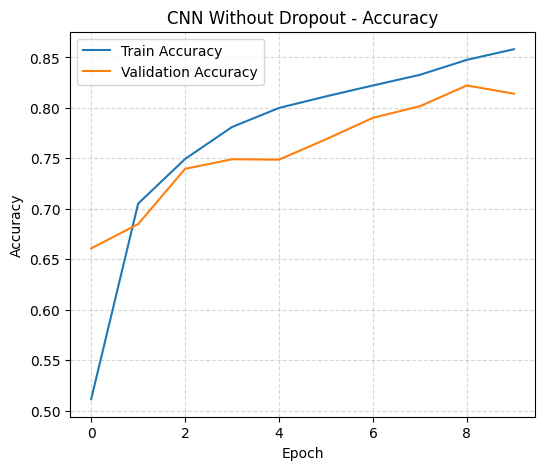

In [52]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,5))
plt.plot(history_no_dropout.history['accuracy'], label='Train Accuracy')
plt.plot(history_no_dropout.history['val_accuracy'], label='Validation Accuracy')
plt.title('CNN Without Dropout - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

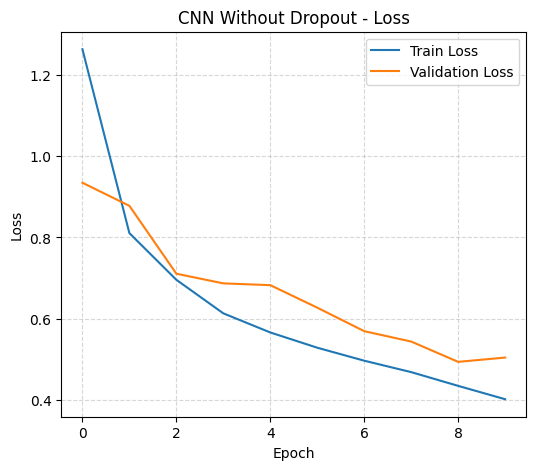

In [53]:
plt.figure(figsize=(6,5))
plt.plot(history_no_dropout.history['loss'], label='Train Loss')
plt.plot(history_no_dropout.history['val_loss'], label='Validation Loss')
plt.title('CNN Without Dropout - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


In [54]:
from sklearn.metrics import classification_report
import numpy as np

# Predict on test set
y_pred = model_no_dropout.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

# Print report
print("\n=== Classification Report (CNN Without Dropout) ===\n")
print(classification_report(y_true_classes, y_pred_classes, target_names=le.classes_))


169/169 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step

=== Classification Report (CNN Without Dropout) ===

                      precision    recall  f1-score   support

          AnnualCrop       0.82      0.87      0.85       600
              Forest       0.97      0.81      0.88       600
HerbaceousVegetation       0.87      0.58      0.70       600
             Highway       0.81      0.57      0.67       500
          Industrial       0.88      0.91      0.89       500
             Pasture       0.84      0.73      0.79       400
       PermanentCrop       0.62      0.82      0.71       500
         Residential       0.85      0.98      0.91       600
               River       0.71      0.86      0.78       500
             SeaLake       0.84      0.97      0.90       600

            accuracy                           0.81      5400
           macro avg       0.82      0.81      0.81      5400
        weighted avg       0.83      0.81      0.81      5400



<Figure size 800x800 with 0 Axes>

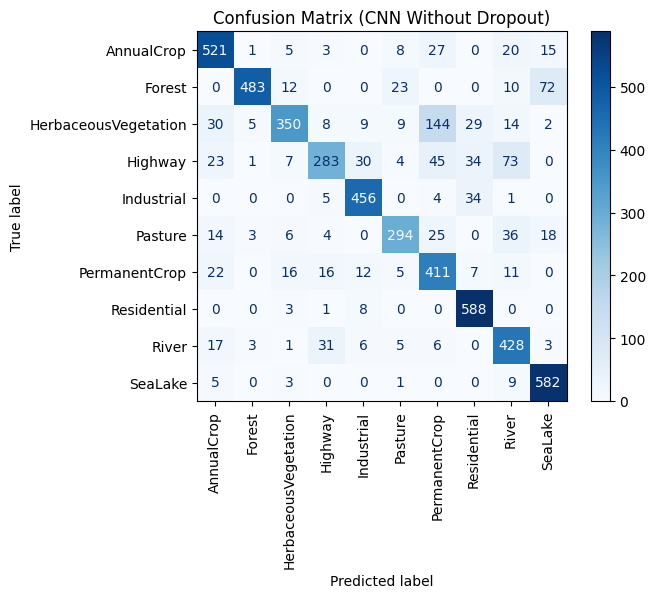

In [55]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true_classes, y_pred_classes)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)

plt.figure(figsize=(8,8))
disp.plot(cmap='Blues', xticks_rotation=90, values_format='d')
plt.title("Confusion Matrix (CNN Without Dropout)")
plt.show()


# CNN With Dropout

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import tensorflow as tf, numpy as np, random


seed = 42
tf.random.set_seed(seed)
np.random.seed(seed)
random.seed(seed)

model_best = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(64, 64, 3)),
    MaxPooling2D(2,2),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),  # single dropout layer
    Dense(len(np.unique(y_encoded)), activation='softmax')
])

model_best.compile(optimizer=Adam(learning_rate=8e-4),
                   loss='categorical_crossentropy',
                   metrics=['accuracy'])

early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history_best = model_best.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=10,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/10
338/338 ━━━━━━━━━━━━━━━━━━━━ 51s 144ms/step - accuracy: 0.3234 - loss: 1.7198 - val_accuracy: 0.6674 - val_loss: 0.9551
Epoch 2/10
338/338 ━━━━━━━━━━━━━━━━━━━━ 44s 129ms/step - accuracy: 0.6099 - loss: 1.0958 - val_accuracy: 0.6589 - val_loss: 0.9054
Epoch 3/10
338/338 ━━━━━━━━━━━━━━━━━━━━ 82s 129ms/step - accuracy: 0.6886 - loss: 0.9018 - val_accuracy: 0.7506 - val_loss: 0.7030
Epoch 4/10
338/338 ━━━━━━━━━━━━━━━━━━━━ 47s 139ms/step - accuracy: 0.7258 - loss: 0.7727 - val_accuracy: 0.7539 - val_loss: 0.6721
Epoch 5/10
338/338 ━━━━━━━━━━━━━━━━━━━━ 48s 142ms/step - accuracy: 0.7563 - loss: 0.7177 - val_accuracy: 0.7815 - val_loss: 0.6065
Epoch 6/10
338/338 ━━━━━━━━━━━━━━━━━━━━ 80s 137ms/step - accuracy: 0.7727 - loss: 0.6473 - val_accuracy: 0.8143 - val_loss: 0.5401
Epoch 7/10
338/338 ━━━━━━━━━━━━━━━━━━━━ 47s 139ms/step - accuracy: 0.7865 - loss: 0.6227 - val_accuracy: 0.8011 - val_loss: 0.5420
Epoch 8/10
338/338 ━━━━━━━━━━━━━━━━━━━━ 47s 140ms/step - accuracy: 0.8018 - loss: 0

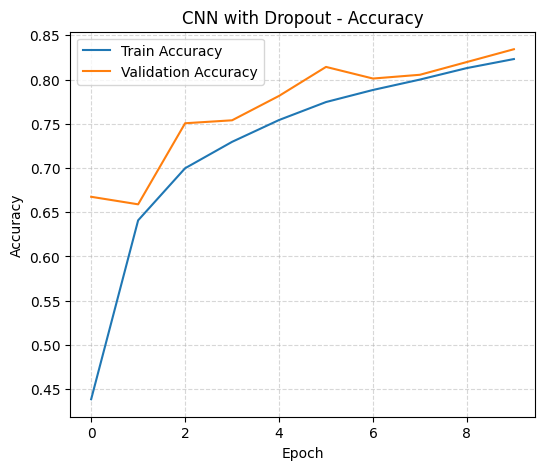

In [57]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,5))
plt.plot(history_best.history['accuracy'], label='Train Accuracy')
plt.plot(history_best.history['val_accuracy'], label='Validation Accuracy')
plt.title('CNN with Dropout - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


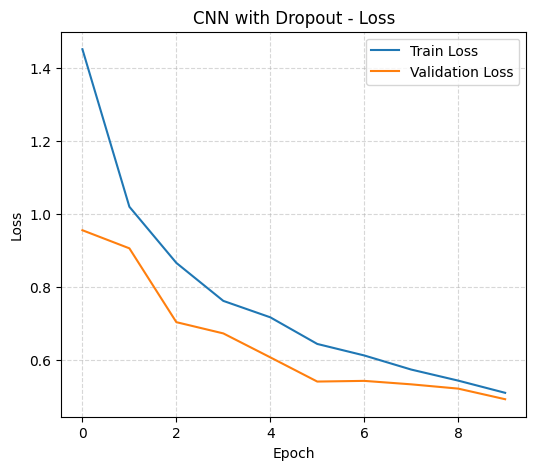

In [58]:
plt.figure(figsize=(6,5))
plt.plot(history_best.history['loss'], label='Train Loss')
plt.plot(history_best.history['val_loss'], label='Validation Loss')
plt.title('CNN with Dropout - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


169/169 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step

=== Classification Report (CNN with Dropout + EarlyStopping) ===

                      precision    recall  f1-score   support

          AnnualCrop       0.93      0.80      0.86       600
              Forest       0.96      0.92      0.94       600
HerbaceousVegetation       0.82      0.69      0.75       600
             Highway       0.66      0.68      0.67       500
          Industrial       0.83      0.98      0.90       500
             Pasture       0.79      0.83      0.81       400
       PermanentCrop       0.68      0.79      0.73       500
         Residential       0.91      0.95      0.93       600
               River       0.78      0.73      0.75       500
             SeaLake       0.94      0.95      0.95       600

            accuracy                           0.83      5400
           macro avg       0.83      0.83      0.83      5400
        weighted avg       0.84      0.83      0.83      5400



<Figure size 800x800 with 0 Axes>

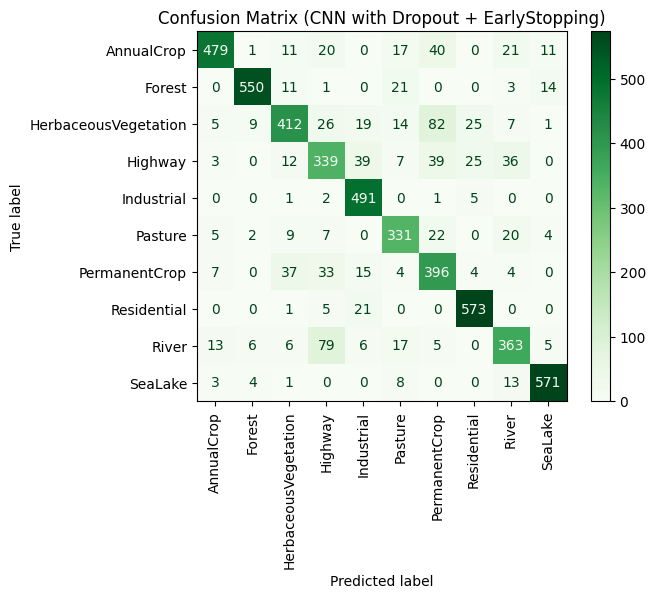

In [59]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np


y_pred = model_best.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

# --- Step 2: Classification report ---
print("\n=== Classification Report (CNN with Dropout + EarlyStopping) ===\n")
print(classification_report(y_true_classes, y_pred_classes, target_names=le.classes_))

# --- Step 3: Confusion Matrix ---
cm = confusion_matrix(y_true_classes, y_pred_classes)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)

plt.figure(figsize=(8,8))
disp.plot(cmap='Greens', xticks_rotation=90, values_format='d')
plt.title("Confusion Matrix (CNN with Dropout + EarlyStopping)")
plt.show()


# With K Fold

In [2]:
import sys
print(sys.executable)


<local-eurosat>\tfenv\Scripts\python.exe


In [3]:
# Install dependencies from requirements.txt before opening this notebook.

     ---------------------------------------- 0.0/38.9 MB ? eta -:--:--
     ---------------------------------------- 0.0/38.9 MB 1.3 MB/s eta 0:00:31
     --------------------------------------- 0.0/38.9 MB 487.6 kB/s eta 0:01:20
     --------------------------------------- 0.0/38.9 MB 487.6 kB/s eta 0:01:20
     --------------------------------------- 0.1/38.9 MB 435.7 kB/s eta 0:01:30
     --------------------------------------- 0.1/38.9 MB 435.7 kB/s eta 0:01:30
     --------------------------------------- 0.1/38.9 MB 435.7 kB/s eta 0:01:30
     --------------------------------------- 0.1/38.9 MB 435.7 kB/s eta 0:01:30
     --------------------------------------- 0.1/38.9 MB 288.1 kB/s eta 0:02:15
     --------------------------------------- 0.1/38.9 MB 288.1 kB/s eta 0:02:15
     --------------------------------------- 0.1/38.9 MB 275.0 kB/s eta 0:02:21
     --------------------------------------- 0.1/38.9 MB 275.0 kB/s eta 0:02:21
     --------------------------------------- 0.1/


[notice] A new release of pip is available: 23.0.1 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import cv2
print(cv2.__version__)


4.12.0


In [6]:
import os
import numpy as np
import cv2
import random
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.optimizers import Adam

In [7]:
import os
import numpy as np

IMG_SIZE = (64, 64)

image_paths = []
labels = []

for label in os.listdir(DATASET):
    class_dir = os.path.join(DATASET, label)
    if os.path.isdir(class_dir):
        for img_name in os.listdir(class_dir):
            img_path = os.path.join(class_dir, img_name)
            image_paths.append(img_path)
            labels.append(label)

image_paths = np.array(image_paths)
labels = np.array(labels)


In [8]:
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical

le = LabelEncoder()
y_encoded = le.fit_transform(labels)
num_classes = len(le.classes_)


In [9]:
import cv2
import tensorflow as tf

def image_generator(image_paths, labels, batch_size=32, shuffle=True):
    num_samples = len(image_paths)

    while True:
        indices = np.arange(num_samples)
        if shuffle:
            np.random.shuffle(indices)

        for start in range(0, num_samples, batch_size):
            end = min(start + batch_size, num_samples)
            batch_idx = indices[start:end]

            batch_images = []
            batch_labels = []

            for i in batch_idx:
                img = cv2.imread(image_paths[i])
                img = cv2.resize(img, IMG_SIZE)
                img = img.astype("float32") / 255.0
                batch_images.append(img)
                batch_labels.append(labels[i])

            batch_images = np.array(batch_images)
            batch_labels = to_categorical(batch_labels, num_classes)

            yield batch_images, batch_labels


In [10]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.optimizers import Adam

def create_model():
    model = Sequential([
        Conv2D(32, (3,3), activation='relu', input_shape=(64, 64, 3)),
        MaxPooling2D(2,2),

        Conv2D(64, (3,3), activation='relu'),
        MaxPooling2D(2,2),

        Conv2D(128, (3,3), activation='relu'),
        MaxPooling2D(2,2),

        Flatten(),
        Dense(128, activation='relu'),
        Dense(num_classes, activation='softmax')
    ])

    model.compile(
        optimizer=Adam(8e-4),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


In [12]:
kf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

fold_histories = []
fold_accuracies = []
fold_indices = []

os.makedirs("weights", exist_ok=True)

fold = 1
for train_idx, val_idx in kf.split(image_paths, y_encoded):
    print(f"\n===== TRAINING FOLD {fold} =====")

    train_paths = image_paths[train_idx]
    val_paths = image_paths[val_idx]

    train_labels = y_encoded[train_idx]
    val_labels = y_encoded[val_idx]

    train_gen = image_generator(train_paths, train_labels, batch_size=32)
    val_gen = image_generator(val_paths, val_labels, batch_size=32, shuffle=False)

    steps_train = len(train_paths) // 32
    steps_val = len(val_paths) // 32

    model = create_model()

    history = model.fit(
        train_gen,
        steps_per_epoch=steps_train,
        validation_data=val_gen,
        validation_steps=steps_val,
        epochs=10
    )

    fold_histories.append(history)
    fold_indices.append((train_idx, val_idx))

    best_acc = max(history.history["val_accuracy"])
    fold_accuracies.append(best_acc)


    model.save_weights(f"weights/fold_{fold}.weights.h5")
    print(f"Saved weights for fold {fold}")


    fold += 1



===== TRAINING FOLD 1 =====
Epoch 1/10


<local-eurosat>\tfenv\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


562/562 ━━━━━━━━━━━━━━━━━━━━ 176s 311ms/step - accuracy: 0.3596 - loss: 1.6221 - val_accuracy: 0.6554 - val_loss: 0.9430
Epoch 2/10
562/562 ━━━━━━━━━━━━━━━━━━━━ 41s 73ms/step - accuracy: 0.6869 - loss: 0.8693 - val_accuracy: 0.7013 - val_loss: 0.7945
Epoch 3/10
562/562 ━━━━━━━━━━━━━━━━━━━━ 42s 74ms/step - accuracy: 0.7579 - loss: 0.6675 - val_accuracy: 0.7529 - val_loss: 0.6786
Epoch 4/10
562/562 ━━━━━━━━━━━━━━━━━━━━ 42s 75ms/step - accuracy: 0.7663 - loss: 0.6484 - val_accuracy: 0.7444 - val_loss: 0.6720
Epoch 5/10
562/562 ━━━━━━━━━━━━━━━━━━━━ 42s 75ms/step - accuracy: 0.7873 - loss: 0.5888 - val_accuracy: 0.7918 - val_loss: 0.5615
Epoch 6/10
562/562 ━━━━━━━━━━━━━━━━━━━━ 44s 78ms/step - accuracy: 0.8093 - loss: 0.5269 - val_accuracy: 0.7842 - val_loss: 0.5878
Epoch 7/10
562/562 ━━━━━━━━━━━━━━━━━━━━ 46s 82ms/step - accuracy: 0.8297 - loss: 0.4842 - val_accuracy: 0.8165 - val_loss: 0.5163
Epoch 8/10
562/562 ━━━━━━━━━━━━━━━━━━━━ 46s 81ms/step - accuracy: 0.8376 - loss: 0.4525 - val_accur

In [14]:
best_fold = np.argmax(fold_accuracies)
print("\n===============================")
print(f"BEST FOLD = {best_fold+1}")
print(f" Accuracy = {fold_accuracies[best_fold]:.4f}")
print("===============================\n")



BEST FOLD = 2
 Accuracy = 0.8429



In [15]:
best_model = create_model()
best_model.load_weights(f"weights/fold_{best_fold+1}.weights.h5")
print("Loaded best fold weights")



Loaded best fold weights


<local-eurosat>\tfenv\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
<local-eurosat>\tfenv\lib\site-packages\keras\src\saving\saving_lib.py:802: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [16]:
val_idx = fold_indices[best_fold][1]
val_paths = image_paths[val_idx]
val_labels = y_encoded[val_idx]

val_gen = image_generator(val_paths, val_labels, batch_size=32, shuffle=False)
steps_val = len(val_paths) // 32 + 1

pred_prob = best_model.predict(val_gen, steps=steps_val)
y_pred = np.argmax(pred_prob, axis=1)
y_true = val_labels[:len(y_pred)]


282/282 ━━━━━━━━━━━━━━━━━━━━ 6s 22ms/step


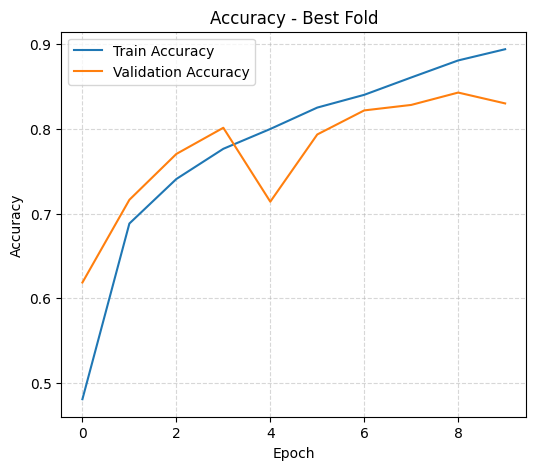

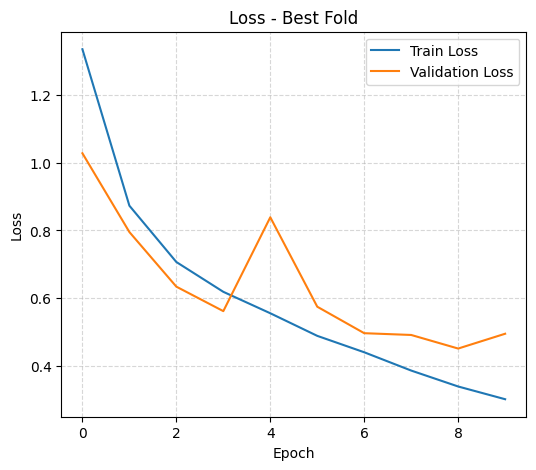

In [17]:
history = fold_histories[best_fold]

plt.figure(figsize=(6,5))
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Accuracy - Best Fold")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

plt.figure(figsize=(6,5))
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Loss - Best Fold")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


In [18]:
print("\n=== Classification Report (Best Fold) ===\n")
print(classification_report(y_true, y_pred, target_names=le.classes_))



=== Classification Report (Best Fold) ===

                      precision    recall  f1-score   support

          AnnualCrop       0.89      0.82      0.86      1000
              Forest       0.87      0.96      0.91      1000
HerbaceousVegetation       0.85      0.65      0.74      1000
             Highway       0.69      0.71      0.70       833
          Industrial       0.90      0.94      0.92       834
             Pasture       0.81      0.83      0.82       666
       PermanentCrop       0.58      0.89      0.70       834
         Residential       0.94      0.96      0.95      1000
               River       0.87      0.64      0.74       833
             SeaLake       0.99      0.87      0.92      1000

            accuracy                           0.83      9000
           macro avg       0.84      0.83      0.83      9000
        weighted avg       0.85      0.83      0.83      9000



<Figure size 800x800 with 0 Axes>

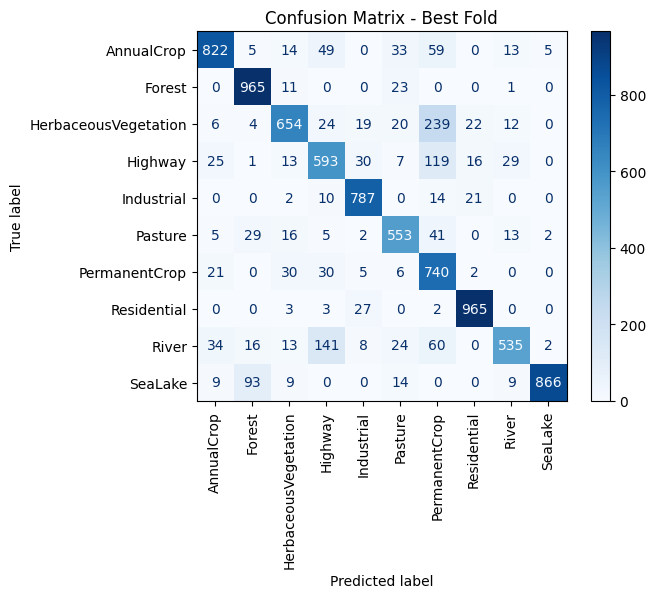

In [19]:
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)

plt.figure(figsize=(8,8))
disp.plot(cmap="Blues", xticks_rotation=90, values_format='d')
plt.title("Confusion Matrix - Best Fold")
plt.show()


# With Droput

In [20]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import tensorflow as tf, numpy as np, random

seed = 42
tf.random.set_seed(seed)
np.random.seed(seed)
random.seed(seed)

def create_dropout_model():
    model = Sequential([
        Conv2D(32, (3,3), activation='relu', input_shape=(64, 64, 3)),
        MaxPooling2D(2,2),

        Conv2D(64, (3,3), activation='relu'),
        MaxPooling2D(2,2),

        Conv2D(128, (3,3), activation='relu'),
        MaxPooling2D(2,2),

        Flatten(),
        Dense(128, activation='relu'),
        Dropout(0.5),  # your dropout layer
        Dense(num_classes, activation='softmax')
    ])

    model.compile(
        optimizer=Adam(learning_rate=8e-4),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model


In [21]:
kf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

dropout_histories = []
dropout_accuracies = []
dropout_indices = []

os.makedirs("dropout_weights", exist_ok=True)

fold = 1
for train_idx, val_idx in kf.split(image_paths, y_encoded):
    print(f"\n===== TRAINING DROPOUT FOLD {fold} =====")

    train_paths = image_paths[train_idx]
    val_paths = image_paths[val_idx]

    train_labels = y_encoded[train_idx]
    val_labels = y_encoded[val_idx]

    train_gen = image_generator(train_paths, train_labels, batch_size=32)
    val_gen = image_generator(val_paths, val_labels, batch_size=32, shuffle=False)

    steps_train = len(train_paths) // 32
    steps_val = len(val_paths) // 32

    model = create_dropout_model()

    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True
    )

    history = model.fit(
        train_gen,
        steps_per_epoch=steps_train,
        validation_data=val_gen,
        validation_steps=steps_val,
        epochs=10,
        callbacks=[early_stop],
        verbose=1
    )

    dropout_histories.append(history)
    dropout_indices.append((train_idx, val_idx))

    best_acc = max(history.history["val_accuracy"])
    dropout_accuracies.append(best_acc)

    model.save_weights(f"dropout_weights/dropout_fold_{fold}.weights.h5")
    print(f"Saved dropout weights for fold {fold}")

    fold += 1



===== TRAINING DROPOUT FOLD 1 =====


<local-eurosat>\tfenv\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
562/562 ━━━━━━━━━━━━━━━━━━━━ 182s 321ms/step - accuracy: 0.3294 - loss: 1.7028 - val_accuracy: 0.5390 - val_loss: 1.1804
Epoch 2/10
562/562 ━━━━━━━━━━━━━━━━━━━━ 45s 79ms/step - accuracy: 0.6232 - loss: 1.0623 - val_accuracy: 0.7015 - val_loss: 0.8220
Epoch 3/10
562/562 ━━━━━━━━━━━━━━━━━━━━ 47s 84ms/step - accuracy: 0.6777 - loss: 0.9252 - val_accuracy: 0.7309 - val_loss: 0.7386
Epoch 4/10
562/562 ━━━━━━━━━━━━━━━━━━━━ 46s 82ms/step - accuracy: 0.7243 - loss: 0.7969 - val_accuracy: 0.6850 - val_loss: 0.8526
Epoch 5/10
562/562 ━━━━━━━━━━━━━━━━━━━━ 46s 82ms/step - accuracy: 0.7536 - loss: 0.7247 - val_accuracy: 0.8225 - val_loss: 0.5121
Epoch 6/10
562/562 ━━━━━━━━━━━━━━━━━━━━ 46s 83ms/step - accuracy: 0.7897 - loss: 0.6249 - val_accuracy: 0.8161 - val_loss: 0.5088
Epoch 7/10
562/562 ━━━━━━━━━━━━━━━━━━━━ 47s 83ms/step - accuracy: 0.7900 - loss: 0.6063 - val_accuracy: 0.8335 - val_loss: 0.4584
Epoch 8/10
562/562 ━━━━━━━━━━━━━━━━━━━━ 46s 82ms/step - accuracy: 0.8152 - loss: 0.5264 

In [23]:
best_dropout_fold = np.argmax(dropout_accuracies)
print("\n================================")
print(f"BEST DROPOUT FOLD = {best_dropout_fold + 1}")
print(f" Accuracy = {dropout_accuracies[best_dropout_fold]:.4f}")
print("================================\n")



BEST DROPOUT FOLD = 1
 Accuracy = 0.8737



In [24]:
model_dropout_best = create_dropout_model()
model_dropout_best.load_weights(
    f"dropout_weights/dropout_fold_{best_dropout_fold+1}.weights.h5"
)
print("Loaded best dropout fold weights")


Loaded best dropout fold weights


<local-eurosat>\tfenv\lib\site-packages\keras\src\saving\saving_lib.py:802: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [25]:
val_idx = dropout_indices[best_dropout_fold][1]
val_paths = image_paths[val_idx]
val_labels = y_encoded[val_idx]

val_gen = image_generator(val_paths, val_labels, batch_size=32, shuffle=False)
steps_val = len(val_paths) // 32 + 1

pred_prob = model_dropout_best.predict(val_gen, steps=steps_val)
y_pred = np.argmax(pred_prob, axis=1)
y_true = val_labels[:len(y_pred)]


282/282 ━━━━━━━━━━━━━━━━━━━━ 77s 273ms/step


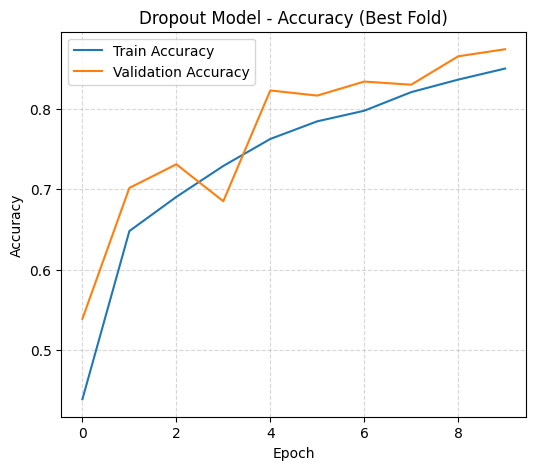

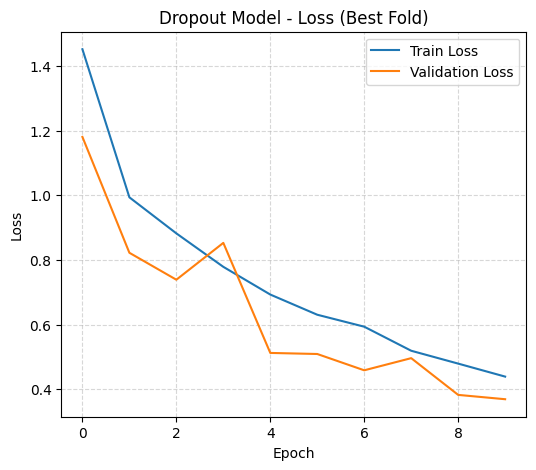

In [26]:
history = dropout_histories[best_dropout_fold]

plt.figure(figsize=(6,5))
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Dropout Model - Accuracy (Best Fold)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

plt.figure(figsize=(6,5))
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Dropout Model - Loss (Best Fold)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


In [27]:
print("\n=== Classification Report (Dropout Best Fold) ===\n")
print(classification_report(y_true, y_pred, target_names=le.classes_))



=== Classification Report (Dropout Best Fold) ===

                      precision    recall  f1-score   support

          AnnualCrop       0.86      0.90      0.88      1000
              Forest       0.96      0.94      0.95      1000
HerbaceousVegetation       0.81      0.82      0.82      1000
             Highway       0.78      0.72      0.75       834
          Industrial       0.89      0.97      0.93       833
             Pasture       0.83      0.89      0.86       667
       PermanentCrop       0.82      0.74      0.78       833
         Residential       0.97      0.94      0.95      1000
               River       0.82      0.80      0.81       833
             SeaLake       0.95      0.98      0.96      1000

            accuracy                           0.87      9000
           macro avg       0.87      0.87      0.87      9000
        weighted avg       0.87      0.87      0.87      9000



<Figure size 800x800 with 0 Axes>

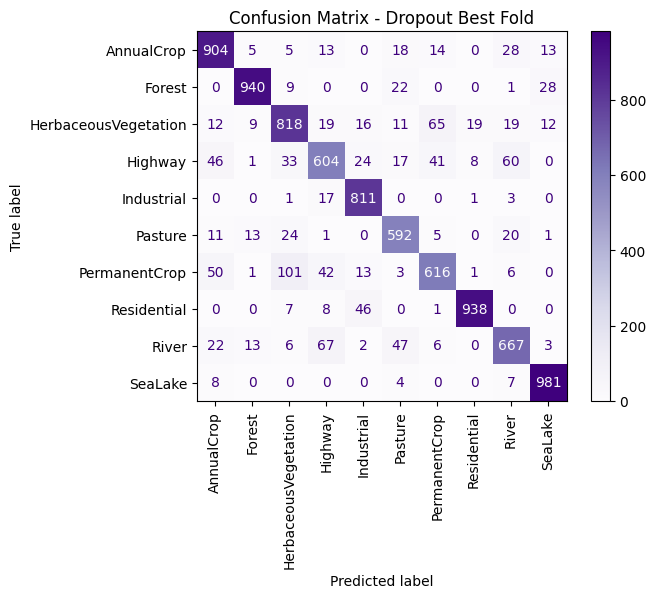

In [28]:
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)

plt.figure(figsize=(8,8))
disp.plot(cmap="Purples", xticks_rotation=90, values_format='d')
plt.title("Confusion Matrix - Dropout Best Fold")
plt.show()
